In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy
import pandas as pd
import traceSpace as tSp

from scipy import optimize, special
from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity

plt.rcParams["figure.figsize"] = (12,8)

In [3]:
x_test = np.zeros(10).reshape((5,2))
print(x_test)

x_test2 = np.arange(100).reshape((5,20))
x_test2_select = [item[0] for item in x_test2]
print(x_test2)
print(x_test2_select)

[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]
[[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
 [20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39]
 [40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]
 [60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79]
 [80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]]
[0, 20, 40, 60, 80]


In [4]:
def read_flux(flux_filename): #return flux in format of list
    filein = open(flux_filename, "r")            # Open file for reading
    inputd = filein.readlines()

    leng = len(inputd)
    print("the number of line of the txt file : " + str(flux_filename) + " list is : " + str(leng))
    inputdata = np.zeros(2*leng).reshape(leng,2)

    for i in range(0,leng):
        tokens = inputd[i].split()
        tokens = np.array(tokens, dtype=np.float64)
        #print(tokens)
        inputdata[i] = tokens
            
    return inputdata

def write_flux(x_data, y_data, output_flux_filename):
    flux_leng = len(x_data)
    file = open(output_flux_filename, 'w')
    for i in range(0,flux_leng):
        file.write(str(x_data[i])+"   "+str(y_data[i])+"\n")
    file.close()
    print("flux written to : "+output_flux_filename)

def get_flux_val(flux, nu_E): #return flux(constant interval) at neutrino energy(interpolation)

    dE_flux = flux[1][0]-flux[0][0]
    E0_flux = flux[0][0]
    nu_E_index = int((nu_E-E0_flux)/dE_flux)
    flux_nu_E = 0
    if(nu_E<flux[-1][0]):
        flux_nu_E = flux[nu_E_index+1][1]*(nu_E-flux[nu_E_index][0])+flux[nu_E_index][1]*(flux[nu_E_index+1][0]-nu_E)
        flux_nu_E = flux_nu_E/(flux[nu_E_index+1][0]-flux[nu_E_index][0])
    
    else:
        flux_nu_E=0

    return flux_nu_E*1e-4 #1e-4 for m^2->cm^2 conversion

def get_flux_val_vect(flux, nu_E_lst):
    flux_val_lst = np.zeros(len(nu_E_lst))
    for i in range(0, len(flux_val_lst)):
        flux_val_lst[i] = get_flux_val(flux, nu_E_lst[i])
    return flux_val_lst

def get_flux_avg(flux):
    avg = 0
    total_flux = 0
    for i in range(0,len(flux)):
        avg = avg + flux[i][0]*flux[i][1]
        total_flux = total_flux + flux[i][1]
        
    avg = avg/total_flux
    
    return avg

def merge_bins(flux,merge_bin):#merge_bin : how many bins to merge to 1 bin ex if merge_bin=2 merge 2 bins into 2
    leng = len(flux)
    print("original flux bin number : "+str(leng))
    div_or_not = 0
    if(leng%merge_bin == 0):
        bin_merged_flux_leng = int(leng/merge_bin)
        div_or_not = 0
    else:
        bin_merged_flux_leng = int(leng/merge_bin) + 1 #make one more bin for leftover
        div_or_not = 1
    print("new bin merged flux bin number : "+str(bin_merged_flux_leng))
    bin_merged_flux = np.zeros(2*bin_merged_flux_leng).reshape((bin_merged_flux_leng, 2))
    
    nu_E_avg = 0
    bin_flux_avg = 0
    for i in range(0,bin_merged_flux_leng-1):
        for j in range(0,merge_bin):
            nu_E_avg = nu_E_avg + flux[i*merge_bin+j][0]
            bin_flux_avg = bin_flux_avg + flux[i*merge_bin+j][1]
        nu_E_avg = nu_E_avg/merge_bin
        bin_flux_avg = bin_flux_avg/merge_bin
        bin_merged_flux[i][0] = nu_E_avg
        bin_merged_flux[i][1] = bin_flux_avg
        nu_E_avg = 0
        bin_flux_avg = 0
        
    left_over_bin_num = 0
    for i in range(0,leng-merge_bin*(bin_merged_flux_leng-1)):#fill the last bin
        nu_E_avg = nu_E_avg + flux[merge_bin*(bin_merged_flux_leng-1)+i][0]
        bin_flux_avg = bin_flux_avg + flux[merge_bin*(bin_merged_flux_leng-1)+i][1]
        left_over_bin_num = left_over_bin_num + 1
        
    nu_E_avg = nu_E_avg/left_over_bin_num
    bin_flux_avg = bin_flux_avg/left_over_bin_num
    bin_merged_flux[-1][0] = nu_E_avg
    bin_merged_flux[-1][1] = bin_flux_avg
    
    return bin_merged_flux

def bin_dif_RMS(target_flux, fit_flux):
    dif_RMS = 0
    for i in range(0,len(target_flux)):
        dif_RMS = dif_RMS + (target_flux[i][1]-get_flux_val(fit_flux, target_flux[i][0]))**2
        
    dif_RMS = dif_RMS/len(target_flux)
    dif_RMS = dif_RMS**0.5
    return dif_RMS

def chi_2_hist(target_flux, fit_flux, flux_uncertainty):
    chi_2 = 0
    for i in range(0,len(target_flux)):
        if not(target_flux[i][1]==0):
            chi_2 = chi_2 + (target_flux[i][1]-get_flux_val(fit_flux, target_flux[i][0]))**2/(target_flux[i][1]+(flux_uncertainty*target_flux[i][1])**2)
        
    return chi_2

In [5]:
nuFlux1p52_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux1p52_nue.txt")
nuFlux2p0_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux2p0_nue.txt")
nuFlux3p04_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p04_nue.txt")
nuFlux3p8_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p8_nue.txt")
nuFlux4p56_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux4p56_nue.txt")
nuFlux5p47_nue_flux = read_flux("nuSTORM_flux_txt_files/nuFlux5p47_nue.txt")

nuFlux1p52_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux1p52_numu.txt")
nuFlux2p0_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux2p0_numu.txt")
nuFlux3p04_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p04_numu.txt")
nuFlux3p8_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p8_numu.txt")
nuFlux4p56_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux4p56_numu.txt")
nuFlux5p47_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux5p47_numu.txt")

PiFlash1p52_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash1p52_numu.txt")
PiFlash2p0_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash2p00_numu.txt")
PiFlash3p04_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash3p04_numu.txt")
PiFlash3p8_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash3p80_numu.txt")
PiFlash4p56_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash4p56_numu.txt")
PiFlash5p47_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash5p47_numu.txt")

nuSTORM_flux_lst = [nuFlux1p52_nue_flux, nuFlux2p0_nue_flux, nuFlux3p04_nue_flux, nuFlux3p8_nue_flux
                    , nuFlux4p56_nue_flux, nuFlux5p47_nue_flux]
nuSTORM_numu_flux_lst = [nuFlux1p52_numu_flux, nuFlux2p0_numu_flux, nuFlux3p04_numu_flux, nuFlux3p8_numu_flux
                    , nuFlux4p56_numu_flux, nuFlux5p47_numu_flux]
nuSTORM_PiFlash_lst = [PiFlash1p52_flux, PiFlash2p0_flux, PiFlash3p04_flux, PiFlash3p8_flux
                       , PiFlash4p56_flux, PiFlash5p47_flux]
E_lst = ['1.52GeV', '2GeV', '3.04GeV', '3.8GeV', '4.56GeV', '5.47GeV']

target_flux = read_flux("nuSTORM_flux_txt_files/T2K_ND280_250kA-nue.dat")
target_anti_nue_flux = read_flux("nuSTORM_flux_txt_files/T2K_ND280_250kA-anue.dat")

DUNE_nue_numode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat")
DUNE_nue_antinumode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat")

print(get_flux_val(nuFlux4p56_nue_flux, 3.5))

the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux1p52_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux2p0_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p04_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p8_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux4p56_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux5p47_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux1p52_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux2p0_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p04_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p8_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux4p56

In [6]:
def sum_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_flux_lst[i], nu_E)
    return sum_flux

def sum_numu_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_numu_flux_lst[i], nu_E)
    return sum_flux

def sum_numu_PiFlash_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_PiFlash_lst[i], nu_E)
    return sum_flux
    
def sum_PiFlash_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_PiFlash_lst[i], nu_E)
    return sum_flux
   

sum_PiFlash_nu_E([1,2,3,4,5,6,7,8], 0.16, 0.16, 0.16, 0.16, 0.16, 0.16)

array([2.08623689e+12, 7.96436109e+11, 1.17531644e+11, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00])

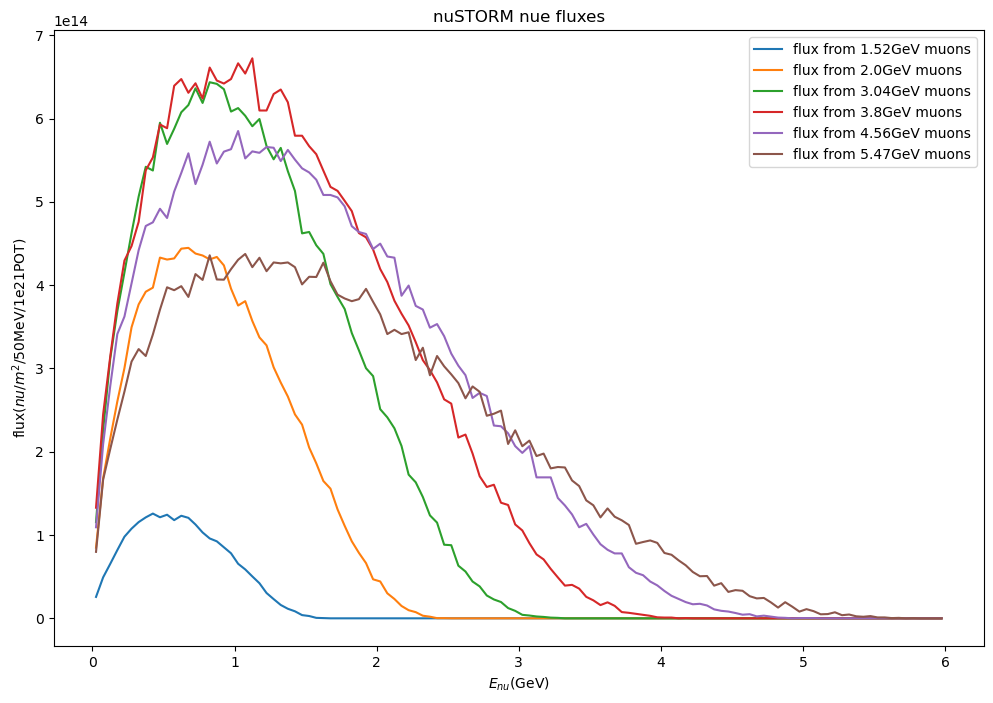

In [7]:
nuSTORM_flux_label_lst = ['flux from 1.52GeV muons', 'flux from 2.0GeV muons', 'flux from 3.04GeV muons'
                          , 'flux from 3.8GeV muons', 'flux from 4.56GeV muons', 'flux from 5.47GeV muons']

for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1],label=nuSTORM_flux_label_lst[i])

plt.title("nuSTORM nue fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

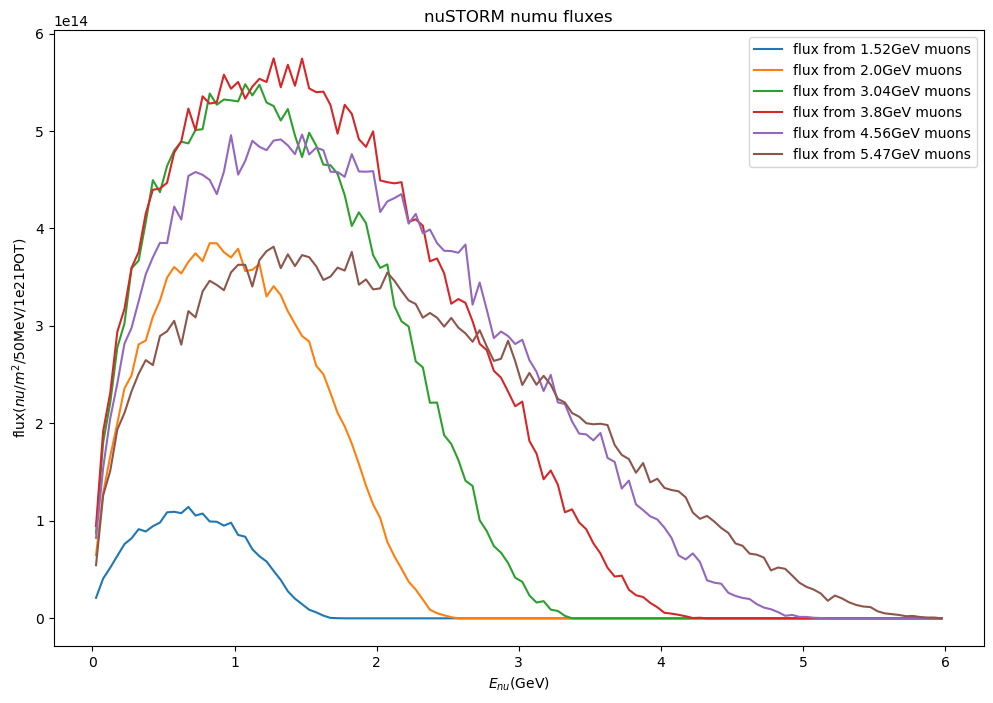

In [8]:
nuSTORM_numu_flux_label_lst = ['flux from 1.52GeV muons', 'flux from 2.0GeV muons', 'flux from 3.04GeV muons'
                          , 'flux from 3.8GeV muons', 'flux from 4.56GeV muons', 'flux from 5.47GeV muons']

for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_numu_flux_lst[i][:,0], nuSTORM_numu_flux_lst[i][:,1],label=nuSTORM_numu_flux_label_lst[i])

plt.title("nuSTORM numu fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

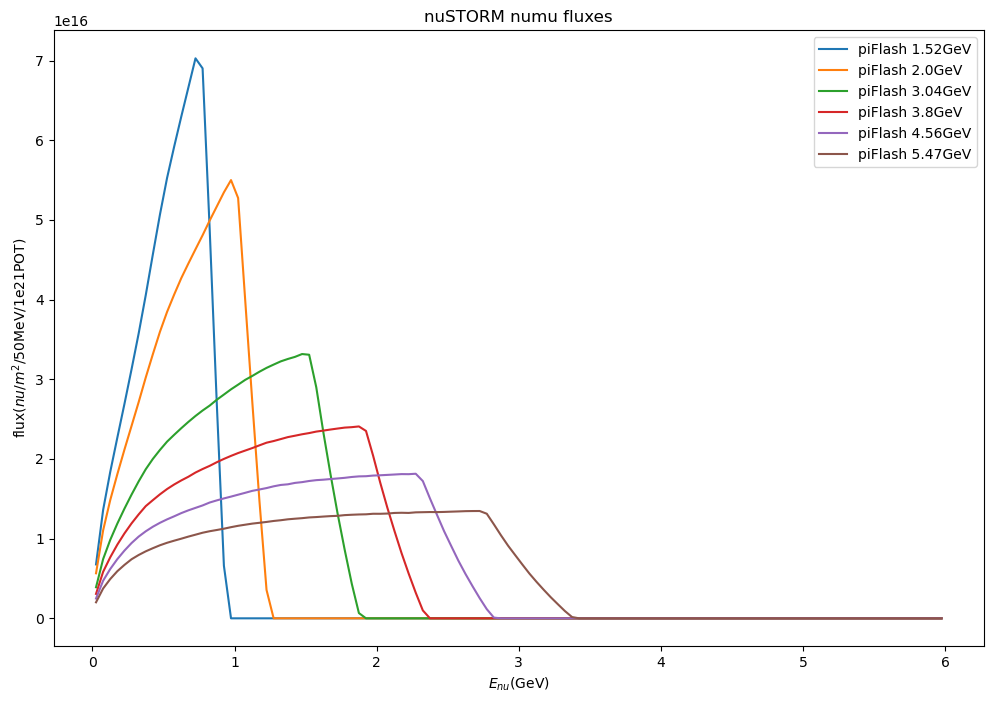

In [9]:
nuSTORM_piFlash_flux_label_lst = ['piFlash 1.52GeV', 'piFlash 2.0GeV', 'piFlash 3.04GeV'
                          , 'piFlash 3.8GeV', 'piFlash 4.56GeV', 'piFlash 5.47GeV']

for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_PiFlash_lst[i][:,0], nuSTORM_PiFlash_lst[i][:,1],label=nuSTORM_piFlash_flux_label_lst[i])

plt.title("nuSTORM numu fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

coeff is : [1, 1, 1, 1, 1, 1]
target flux $E_{nu}$ avg : 1.2859282713029636 GeV fit flux $E_{nu}$ avg : 1.3961246961276126 GeV


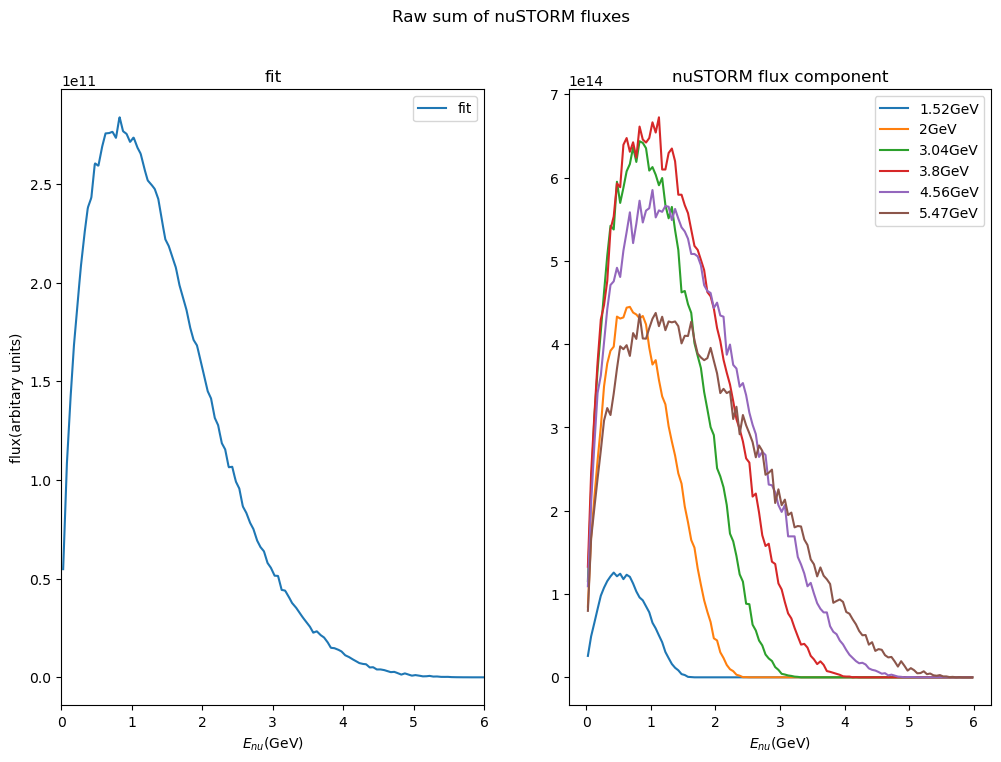

In [10]:
fit_lst_leng = 5000
pars = [1,1,1,1,1,1]
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *pars) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")


plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Raw sum of nuSTORM fluxes')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

#ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

[5.975e+00 9.680e+07]


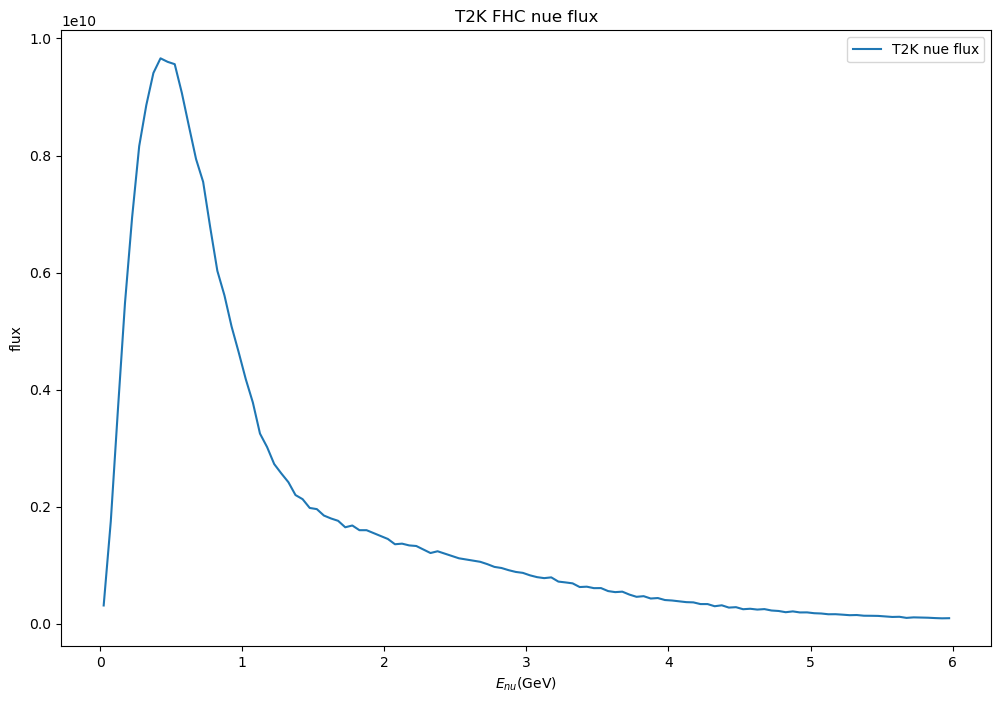

In [11]:
print(target_flux[119])
target_flux = target_flux[:120]
plt.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
plt.title("T2K FHC nue flux")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux")
plt.legend()
plt.show()

In [12]:
#original scipy optimize.curve_fit
#====================================================================================




In [13]:
sigma_array = np.zeros(len(target_flux[:,1]))
sigma_array = target_flux[:,1]**0.5 #+0.1*target_flux[:,1]
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1

sigma_array = 1
pars, cov=optimize.curve_fit(sum_flux_nu_E, target_flux[:,0], target_flux[:,1], p0=[ 7.39545089e-01,-9.27494391e-02, 5.51358513e-02,-2.79184563e-02, -6.00695425e-04, 4.93489427e-02],method='lm',sigma=sigma_array,maxfev=2500) #fit
print("coeff is : "+np.array2string(pars, separator=","))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))
print("Uncertainty % is : "+str(100*np.sqrt(cov.diagonal())/pars))

coeff is : [ 7.39545089e-01,-9.27494391e-02, 5.51358513e-02,-2.79184563e-02,
 -6.00695425e-04, 4.93489427e-02]
Uncertainty is : [0.03739521 0.02625632 0.02787999 0.02978439 0.0323554  0.02076357]
Uncertainty % is : [ 5.05651497e+00 -2.83088746e+01  5.05659894e+01 -1.06683528e+02
 -5.38632304e+03  4.20750135e+01]


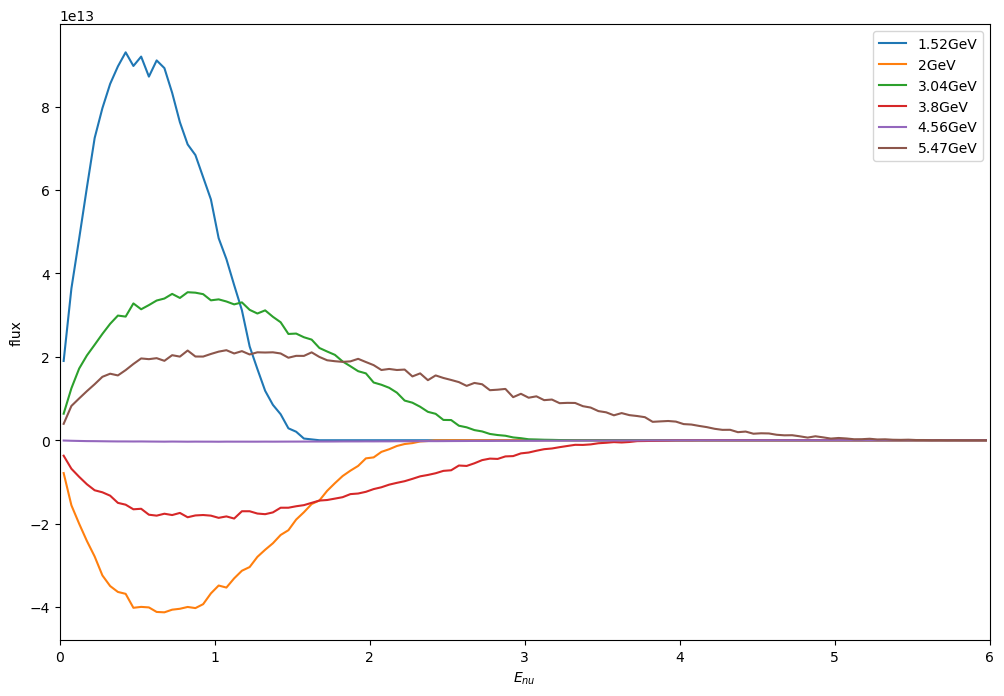

In [14]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 7.39545089e-01 -9.27494391e-02  5.51358513e-02 -2.79184563e-02
 -6.00695425e-04  4.93489427e-02]
Uncertainty is : [0.03739521 0.02625632 0.02787999 0.02978439 0.0323554  0.02076357]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.1461675219170184 GeV
chi^2 of bin diff : 1.1998E+04


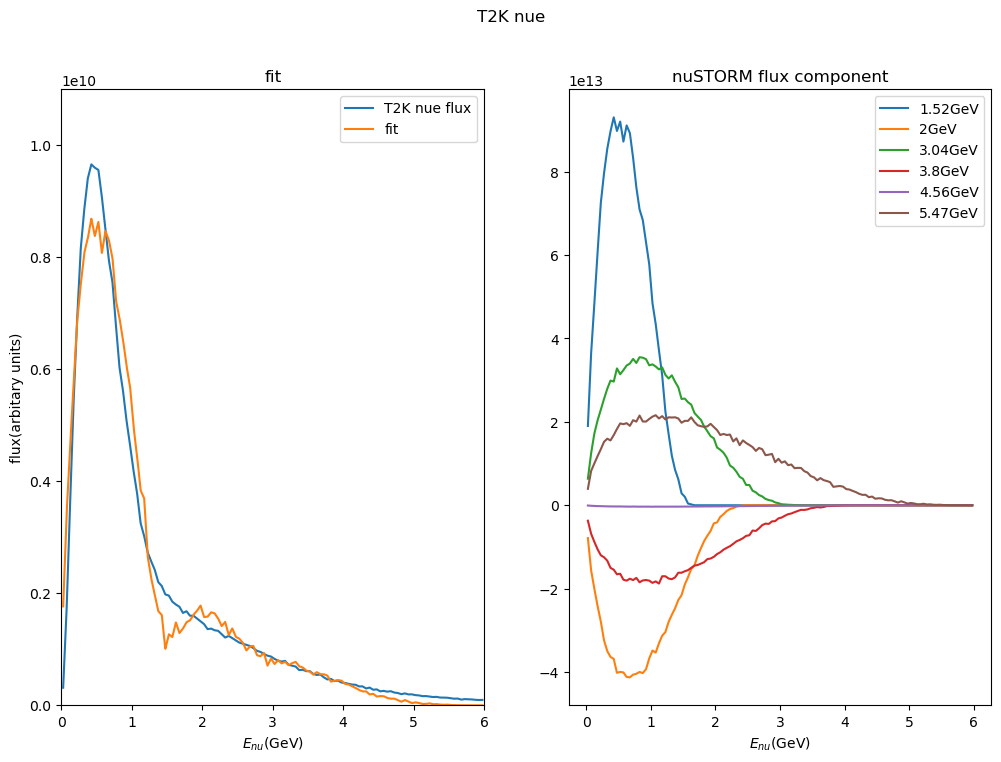

In [15]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *pars) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [16]:
a = np.arange(0,10)
print(a)
def test_flatten(lst):
    return [*a]

print(test_flatten(a))

[0 1 2 3 4 5 6 7 8 9]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [17]:
#least square method
#first test if possible to reproduce curve_fit results

In [18]:
"""
def sum_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_flux_lst[i], nu_E)
    return sum_flux
"""

def nue_opt_fun(coeff_lst, nu_E, y, sigma = 1.): #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    trans = 1/sigma
    return trans*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

nue_opt_fun(np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0]), [1.5], 1e10)

array([2.10144637e+11])

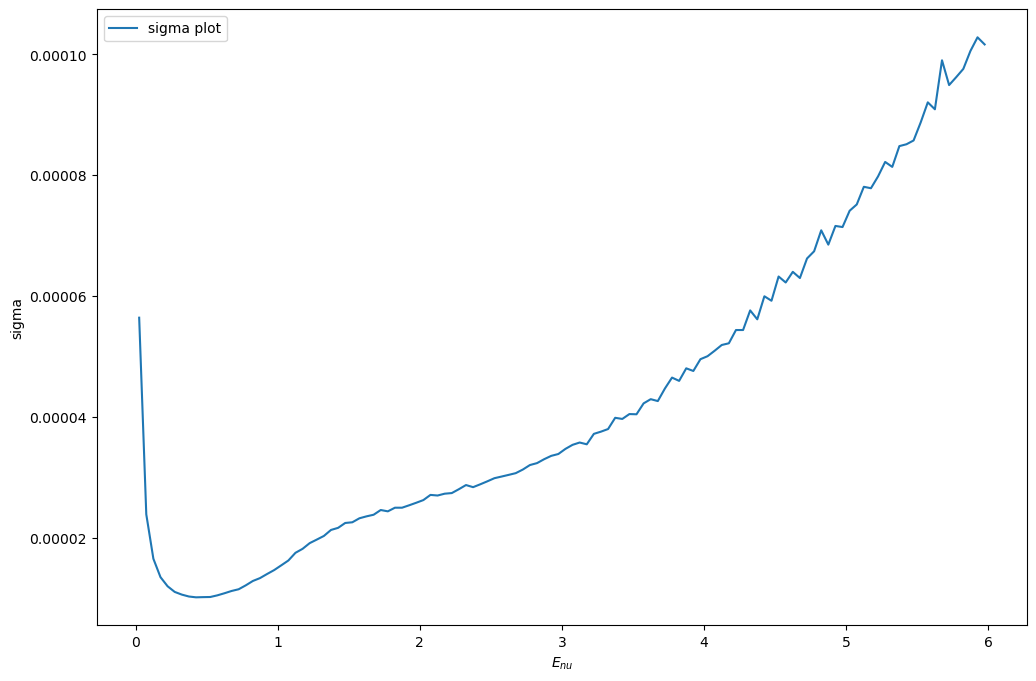

     message: `ftol` termination condition is satisfied.
     success: True
      status: 2
         fun: [ 2.767e+13  7.785e+13 ... -9.201e+11 -9.524e+11]
           x: [ 8.820e-01 -1.432e-01  5.576e-02 -2.260e-03 -1.988e-02
                5.353e-02]
        cost: 4.45673036589894e+28
         jac: [[ 4.555e+13  1.504e+14 ...  1.937e+14  1.414e+14]
               [ 2.058e+14  7.034e+14 ...  8.746e+14  6.969e+14]
               ...
               [ 0.000e+00 -0.000e+00 ... -0.000e+00  0.000e+00]
               [ 0.000e+00 -0.000e+00 ... -0.000e+00  0.000e+00]]
        grad: [-2.041e+21  4.050e+21 -2.589e+20 -6.698e+19 -2.210e+20
               -2.758e+20]
  optimality: 4.04952510973454e+21
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 3
        njev: 3


In [19]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])

sigma_array = np.zeros(len(target_flux[:,1]))
sigma_array = target_flux[:,1]**0.5 #+0.1*target_flux[:,1]
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
    else:
        sigma_array[i] = 1/sigma_array[i]

#print(sigma_array)
plt.plot(target_flux[:,0],sigma_array,label='sigma plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("sigma")
plt.legend()
plt.show()
fit_lsq_sim = optimize.least_squares(nue_opt_fun, pars_0, args=(target_flux[:,0], target_flux[:,1],sigma_array))#, loss='cauchy', f_scale=0.1

print(fit_lsq_sim)

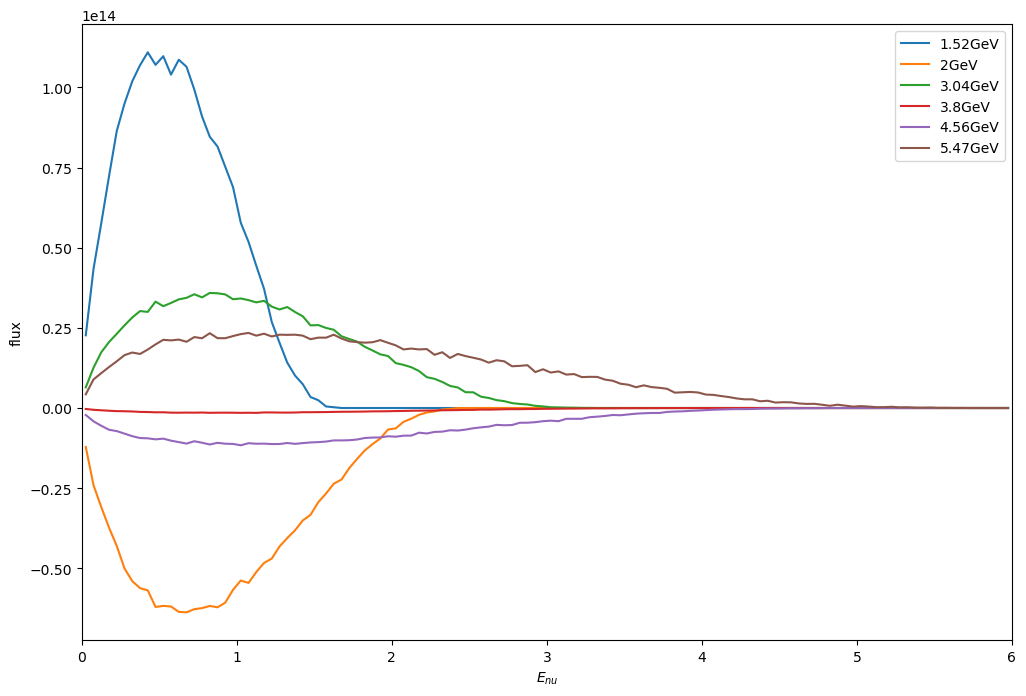

In [20]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 0.8820309  -0.14324808  0.0557565  -0.00226034 -0.01987519  0.05352694]
Uncertainty is : [0.03739521 0.02625632 0.02787999 0.02978439 0.0323554  0.02076357]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.128469314988788 GeV
chi^2 of bin diff : 1.1998E+04


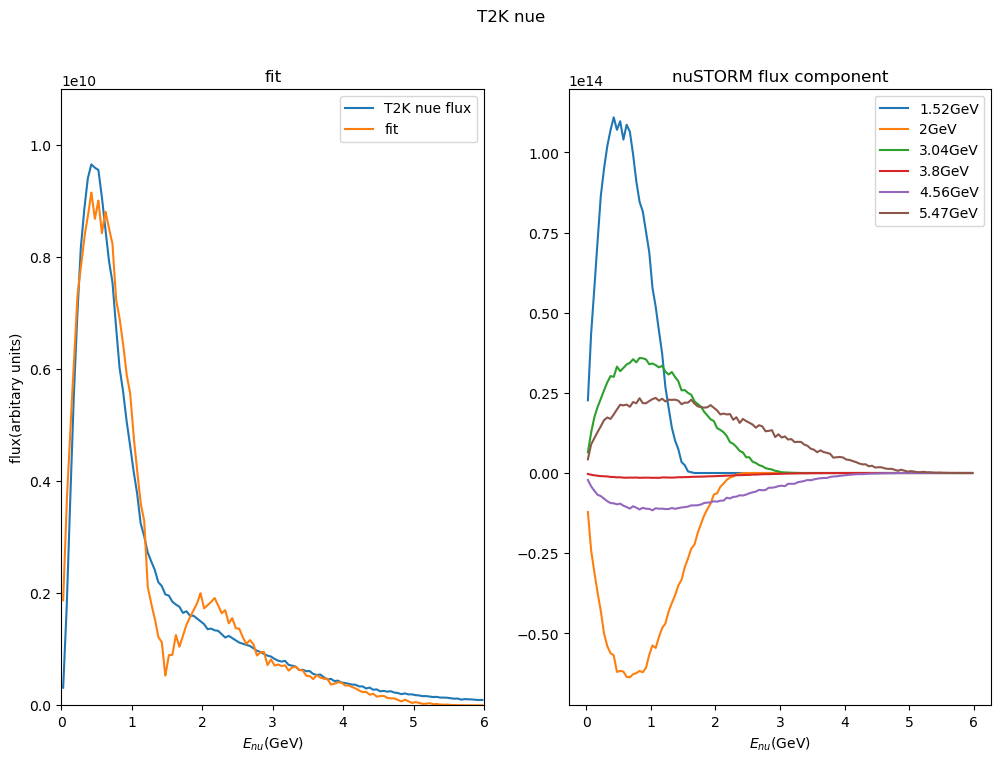

In [21]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_sim.x) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_sim.x))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [22]:
np.abs(-1)

1

In [23]:
#least square method
#implement nuSTORM flux uncertainty

In [24]:
"""
def sum_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    sum_flux = np.zeros(len(nu_E))
    for i in range(len(coeff_lst)):
        sum_flux = sum_flux + coeff_lst[i]*get_flux_val_vect(nuSTORM_flux_lst[i], nu_E)
    return sum_flux
"""
def nue_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    sigma = np.zeros(len(nu_E))
    if uniform_sigma:
        for i in range(0,len(nu_E)):
            sigma[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            sigma[i] = sigma[i] + ((np.sqrt(y[i])+y[i]*beam_uncert)/y[i])**2
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                #print(flux_val)
                if not((flux_val == 0.0) or (coeff_lst[j] == 0)):
                    sigma[i] = sigma[i] + (coeff_lst[j]*((np.sqrt(flux_val)+flux_val*beam_uncert)/flux_val))**2
            #print(str(sigma[i])+", "+str(nu_E[i]))
            sigma[i] = np.abs(sigma[i])**0.5
            
    return sigma

def nue_opt_flux_sigma_fun(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    sigma = np.zeros(len(nu_E))
    sigma = nue_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert, uniform_sigma)
    
    weight = 1/sigma
    #print(trans)
    return weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

[5.98102797e-05 2.78640339e-05 2.06959448e-05 1.74838430e-05
 1.57230093e-05 1.47080468e-05 1.41507657e-05 1.37687654e-05
 1.35585496e-05 1.36836174e-05 1.36264697e-05 1.39899724e-05
 1.41240589e-05 1.44723038e-05 1.48933004e-05 1.56598451e-05
 1.64488585e-05 1.69367014e-05 1.77347016e-05 1.85464084e-05
 1.98025112e-05 2.08545051e-05 2.25044279e-05 2.38350658e-05
 2.63497063e-05 2.86499862e-05 3.21573035e-05 3.63546664e-05
 4.06054503e-05 5.54258521e-05 6.40574075e-05 1.36003852e-04
 1.90961472e-04 2.39000133e-05 2.46902389e-05 2.44817184e-05
 2.50974305e-05 2.51133422e-05 2.55308582e-05 2.59985886e-05
 2.64475169e-05 2.73775786e-05 2.73533217e-05 2.78316590e-05
 2.81903919e-05 2.90441680e-05 3.09650547e-05 3.19046665e-05
 5.42155104e-05 5.44820963e-05 2.99017049e-05 3.01786336e-05
 3.04593942e-05 3.07517685e-05 3.13525064e-05 3.21136007e-05
 3.24413165e-05 3.30960402e-05 3.36890657e-05 3.40346432e-05
 3.50397727e-05 3.57760349e-05 3.63382121e-05 3.62314474e-05
 3.86162818e-05 3.964212

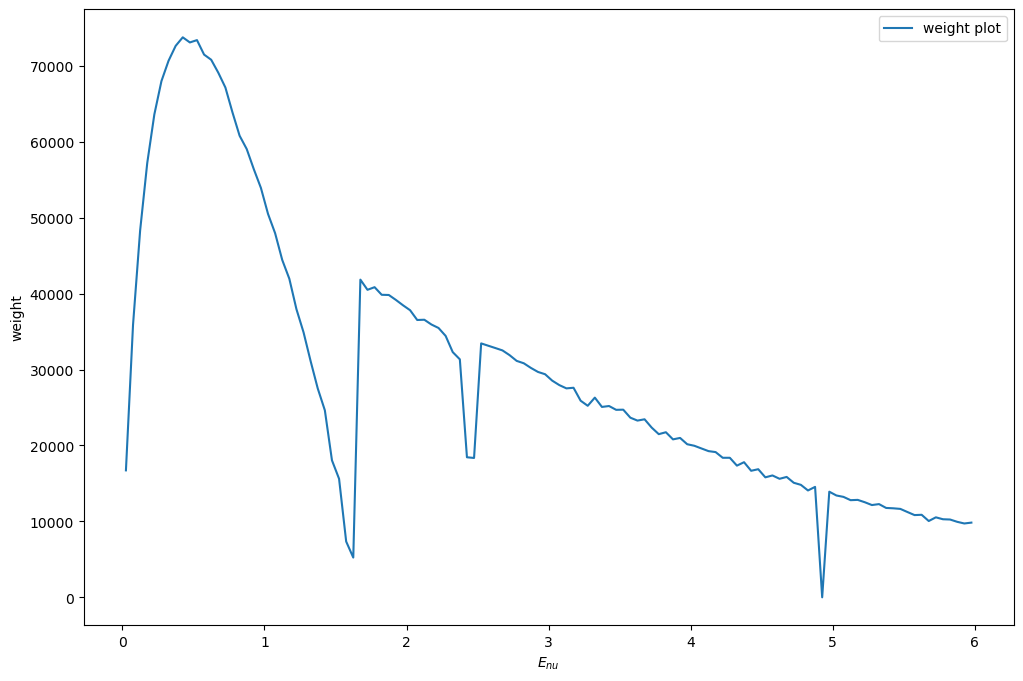

     message: `ftol` termination condition is satisfied.
     success: True
      status: 2
         fun: [ 2.605e+13  6.742e+13 ... -9.201e+11 -9.524e+11]
           x: [ 9.962e-01 -2.026e-01  9.418e-02 -1.409e-02 -4.144e-02
                7.317e-02]
        cost: 2.4774829737671704e+28
         jac: [[ 4.015e+13  1.421e+14 ...  1.828e+14  1.334e+14]
               [ 1.590e+14  6.045e+14 ...  7.505e+14  5.975e+14]
               ...
               [ 0.000e+00 -0.000e+00 ... -0.000e+00  0.000e+00]
               [ 0.000e+00 -0.000e+00 ... -0.000e+00  0.000e+00]]
        grad: [-1.761e+23 -1.825e+24 -2.878e+24 -3.194e+24 -2.720e+24
               -2.011e+24]
  optimality: 3.1938708757219763e+24
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 7
        njev: 7


In [25]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_sigma_fun, pars_0, args=(target_flux[:,0], target_flux[:,1],flux_uncert,False))#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False))
plt.plot(target_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

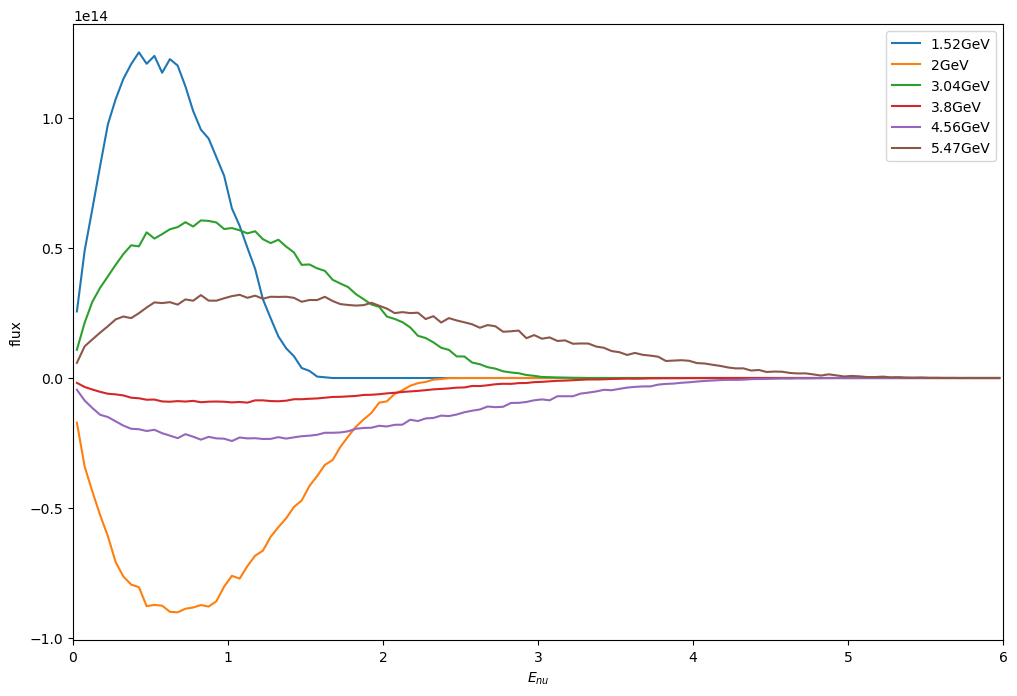

In [26]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_T2K_imitate.txt
coeff is : [ 0.99620743 -0.20264036  0.09417775 -0.01408901 -0.0414428   0.07316764]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.1312609864739567 GeV
chi^2 of bin diff : 1.1998E+04


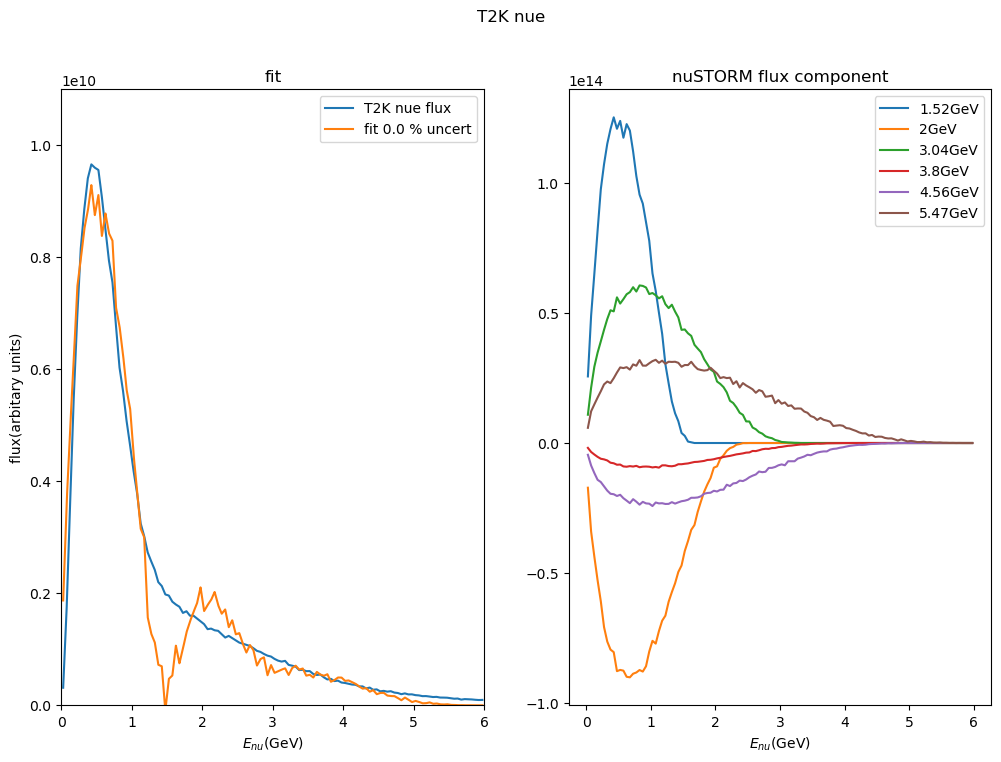

In [27]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_T2K_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [28]:
"""
Rohan's FOM( figure of merit )
f:target flux
FOM = Sigma((f(E_nu)-flux_sum(E_nu))^2/(A+B*f(E_nu)^2)
"""
A=1
B=1e-20
def nue_opt_all_flux_get_FOM_rohan(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    
    weight = np.zeros(len(nu_E))
    if uniform_weight:
        for i in range(0,len(nu_E)):
            weight[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            flux_sum = 0
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                flux_sum = flux_sum + flux_val*coeff_lst[j]
            
            weight[i] = (y[i]-flux_sum)**2/(A+B*y[i]**2)
            #print(str(weight[i])+", "+str(nu_E[i]))
            
    return weight

def nue_opt_flux_FOM_fun_rohan(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    weight = np.zeros(len(nu_E))
    weight = nue_opt_all_flux_get_FOM_rohan(coeff_lst, nu_E, y, beam_uncert, uniform_weight)
    
    #print(sum(weight))
    return sum(weight)#weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

[1.95429510e+18 2.49165135e+18 6.86503149e+17 1.44407127e+16
 5.48944641e+16 4.29295132e+17 5.48840301e+17 8.99554943e+17
 7.79771886e+17 1.08056135e+18 7.19979730e+17 8.09488509e+17
 3.93647813e+16 1.79646125e+16 3.71731008e+16 7.07659726e+16
 4.29979889e+17 5.03106581e+17 6.57676892e+17 7.83210438e+17
 4.81868594e+17 3.64023977e+17 3.10621435e+17 4.67200746e+17
 3.05575413e+14 4.45817336e+16 1.25255359e+17 1.63388189e+17
 1.60502803e+17 7.01768757e+17 3.41425681e+17 2.87291495e+17
 6.58503500e+16 1.57315725e+17 5.28794508e+16 2.75733707e+16
 6.22679481e+15 2.21075385e+14 1.45356915e+16 5.92280187e+16
 1.19995153e+16 3.80128547e+16 7.04215810e+16 6.40643799e+16
 3.27086595e+16 1.17377701e+16 5.96889794e+16 4.07725352e+14
 2.07574500e+16 1.78587350e+15 1.74782518e+15 2.95214878e+13
 1.31289511e+16 1.09124602e+15 1.34916649e+15 4.76781466e+15
 8.28289196e+15 2.70127842e+14 3.05293492e+16 1.04159199e+15
 7.32939517e+15 6.67803691e+14 5.96609182e+14 5.07650562e+13
 2.13005896e+14 3.071308

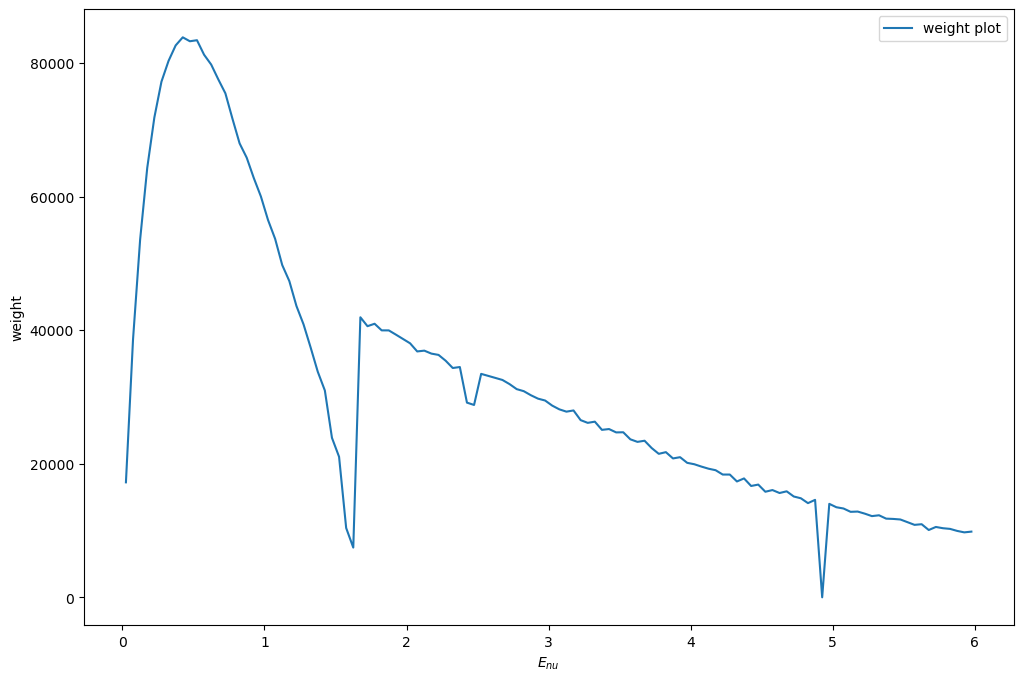

     message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [ 1.776e+19]
           x: [ 6.949e-01 -8.178e-02  5.425e-02 -3.265e-02  5.005e-03
                4.672e-02]
        cost: 1.5779239489080587e+38
         jac: [[ 2.145e+17 -1.143e+17  2.739e+17 -9.715e+16  2.570e+17
                 1.452e+16]]
        grad: [ 3.810e+36 -2.030e+36  4.865e+36 -1.726e+36  4.566e+36
                2.580e+35]
  optimality: 4.8652676949435584e+36
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 20000
        njev: 19718


In [29]:
pars_0 = np.array([1.0, -1.0, 1.0, -1.0, 1.0, -1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_FOM_fun_rohan, pars_0, args=(target_flux[:,0], target_flux[:,1],flux_uncert,False), max_nfev=20000)#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_FOM_rohan(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False))
plt.plot(target_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

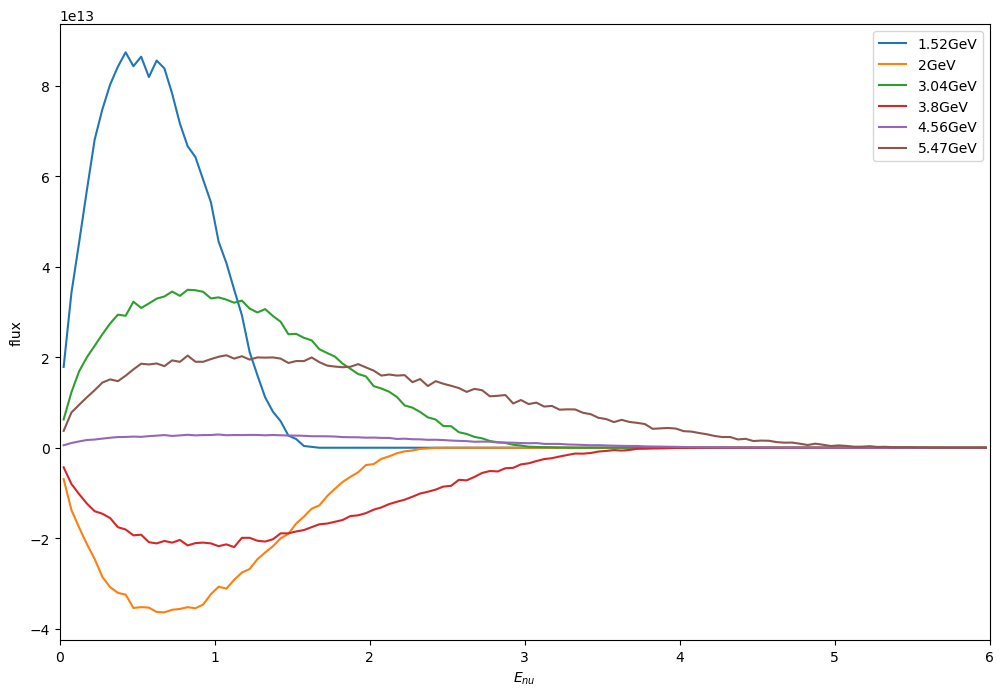

In [30]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_T2K_imitate.txt
coeff is : [ 0.69493011 -0.0817831   0.05424961 -0.03265417  0.0050048   0.04672391]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.1553447664009555 GeV
chi^2 of bin diff : 1.1998E+04


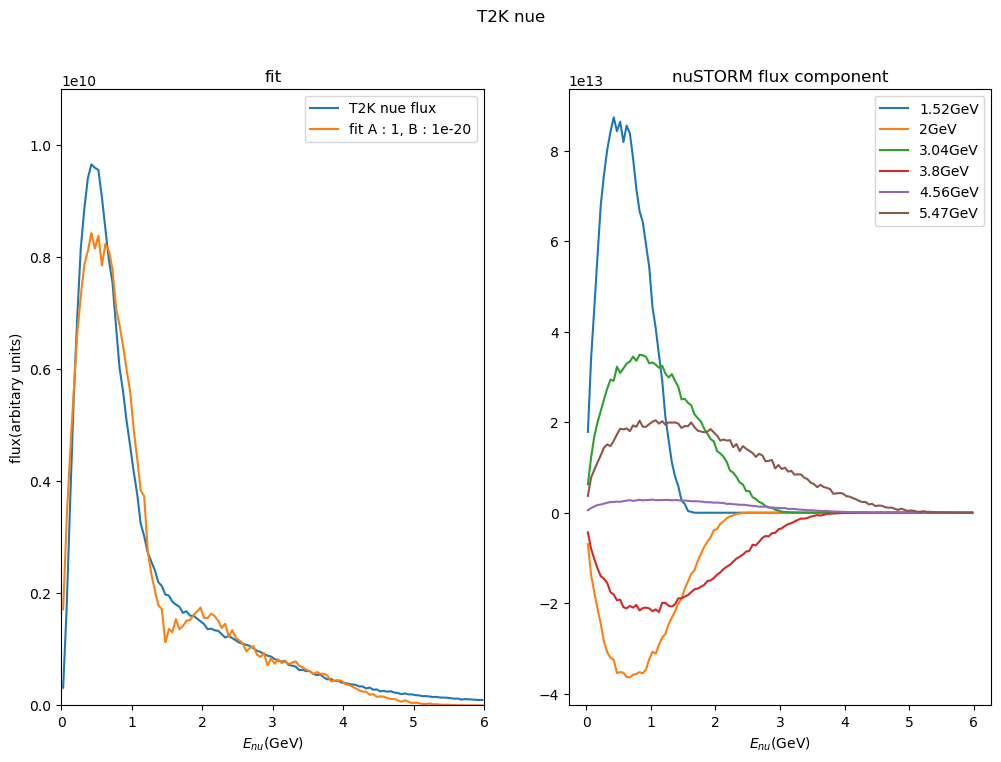

In [31]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_T2K_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

#fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
fit_tit = 'fit A : '+str(A)+', B : '+str(B)
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [32]:
x = np.array([1,2,3,4,5])
x**2

array([ 1,  4,  9, 16, 25])

In [33]:
"""
DUNE PRISM Tikhonov regularization
f:target flux
"""
def nue_opt_all_flux_get_FOM_DUNE_PRISM(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    T_para = 1e5
    weight = np.zeros(len(nu_E))
    if uniform_weight:
        for i in range(0,len(nu_E)):
            weight[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            flux_sum = 0
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                flux_sum = flux_sum + flux_val*coeff_lst[j] 
            
            weight[i] = (y[i]-flux_sum)**2
            #for j in range(0,len(coeff_lst)):
                #weight[i] =  weight[i]+ (T_para*coeff_lst[j])**2
            for j in range(0,len(coeff_lst)-1):
                weight[i] = (y[i]-flux_sum)**2 + (T_para*coeff_lst[j]-T_para*coeff_lst[j+1])**2
            #print(str(weight[i])+", "+str(nu_E[i]))
            
    return weight

def nue_opt_flux_FOM_fun_DUNE_PRISM(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    weight = np.zeros(len(nu_E))
    weight = nue_opt_all_flux_get_FOM_DUNE_PRISM(coeff_lst, nu_E, y, beam_uncert, uniform_weight)
    
    #print(sum(weight))
    return sum(weight)#weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

[2.10611646e+18 2.80052594e+18 9.08099728e+17 7.15694544e+16
 2.96301811e+15 2.42318252e+17 3.33523378e+17 5.99606594e+17
 4.82589685e+17 7.72284682e+17 4.52634791e+17 5.46420345e+17
 7.27968689e+14 8.24184342e+16 1.23402940e+17 1.42495971e+17
 5.74338997e+17 6.33673925e+17 7.61740026e+17 8.94734935e+17
 5.25908069e+17 3.70773724e+17 3.01759294e+17 4.21178558e+17
 5.34555165e+15 8.90383446e+16 1.92852571e+17 2.57619200e+17
 2.56241234e+17 9.25418099e+17 4.61349904e+17 3.85766023e+17
 9.83413932e+16 2.15164405e+17 7.52019093e+16 3.59566577e+16
 6.51216369e+15 4.15349796e+14 1.90619157e+16 7.98682468e+16
 1.64611122e+16 5.09150708e+16 8.75621775e+16 9.20195810e+16
 4.80507705e+16 2.08872823e+16 7.83518259e+16 9.85032218e+13
 2.98620672e+16 3.80395424e+15 4.49760450e+15 2.51060566e+14
 1.07695133e+16 2.81702945e+14 1.49255261e+15 6.20695558e+15
 7.11819256e+15 2.79666302e+14 3.32623655e+16 1.40039366e+15
 8.99892343e+15 8.72878673e+13 1.06047100e+15 2.76630865e+14
 7.69181310e+12 2.153938

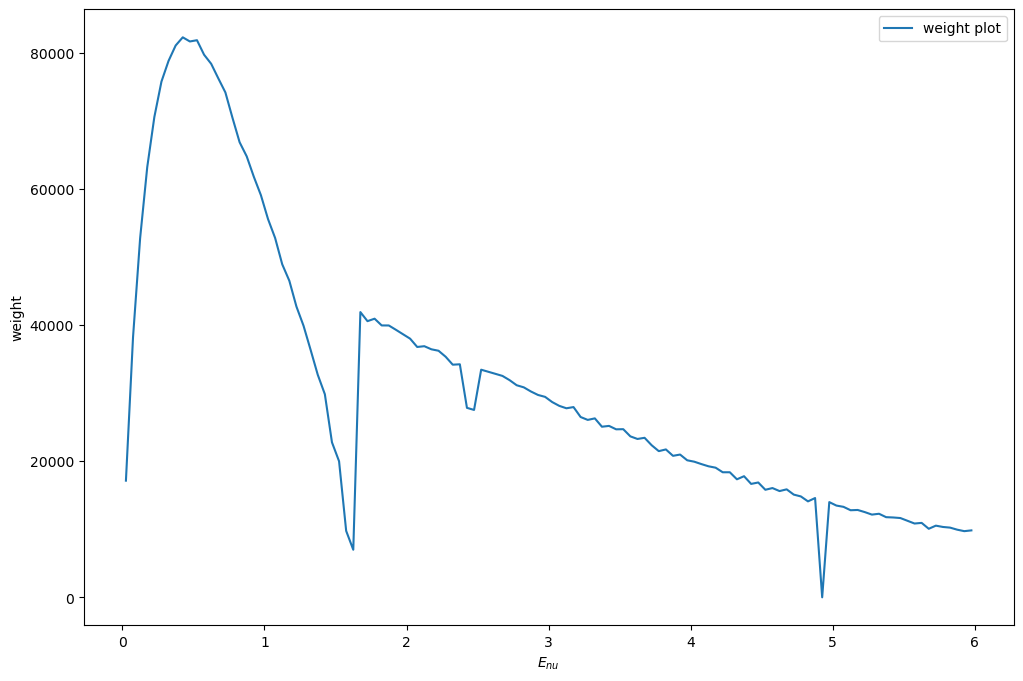

     message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [ 2.282e+19]
           x: [ 7.414e-01 -9.427e-02  5.679e-02 -2.948e-02  4.231e-04
                4.900e-02]
        cost: 2.6045741398832027e+38
         jac: [[ 2.890e+17 -1.625e+17  3.497e+17 -1.111e+17  2.704e+17
                 3.596e+16]]
        grad: [ 6.596e+36 -3.710e+36  7.981e+36 -2.537e+36  6.172e+36
                8.208e+35]
  optimality: 7.980656968235349e+36
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 20000
        njev: 19718


In [34]:
pars_0 = np.array([1.0, -1.0, 1.0, -1.0, 1.0, -1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_FOM_fun_DUNE_PRISM, pars_0, args=(target_flux[:,0], target_flux[:,1],flux_uncert,False), max_nfev=20000)#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_FOM_rohan(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False))
plt.plot(target_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

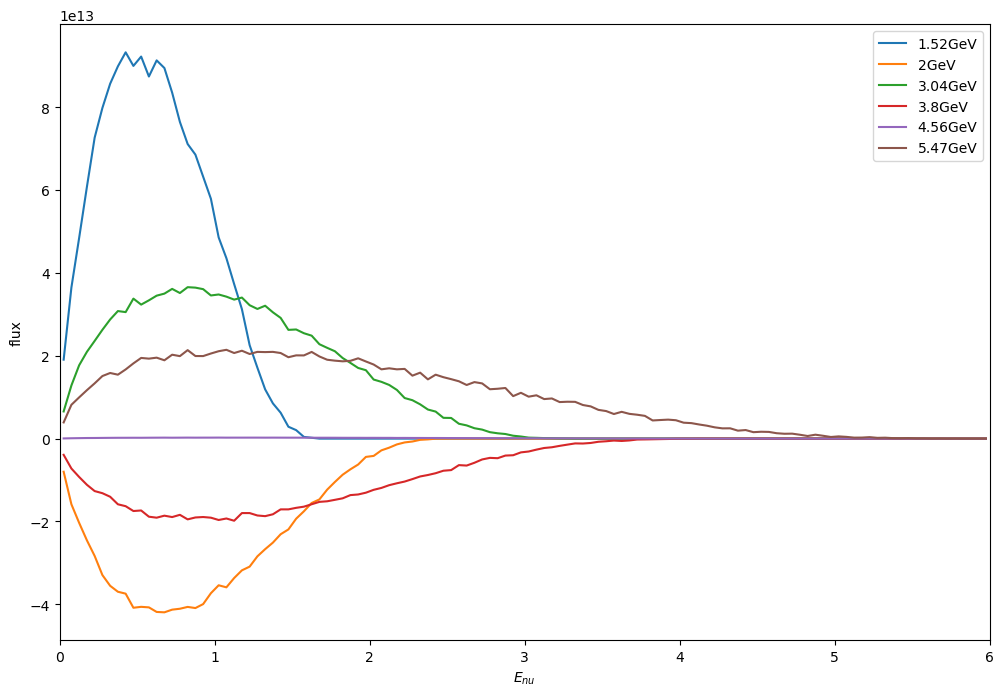

In [35]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_T2K_imitate.txt
coeff is : [ 7.41444766e-01 -9.42654980e-02  5.67938100e-02 -2.94767825e-02
  4.23113955e-04  4.90040021e-02]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.1460558572376929 GeV
chi^2 of bin diff : 1.1998E+04


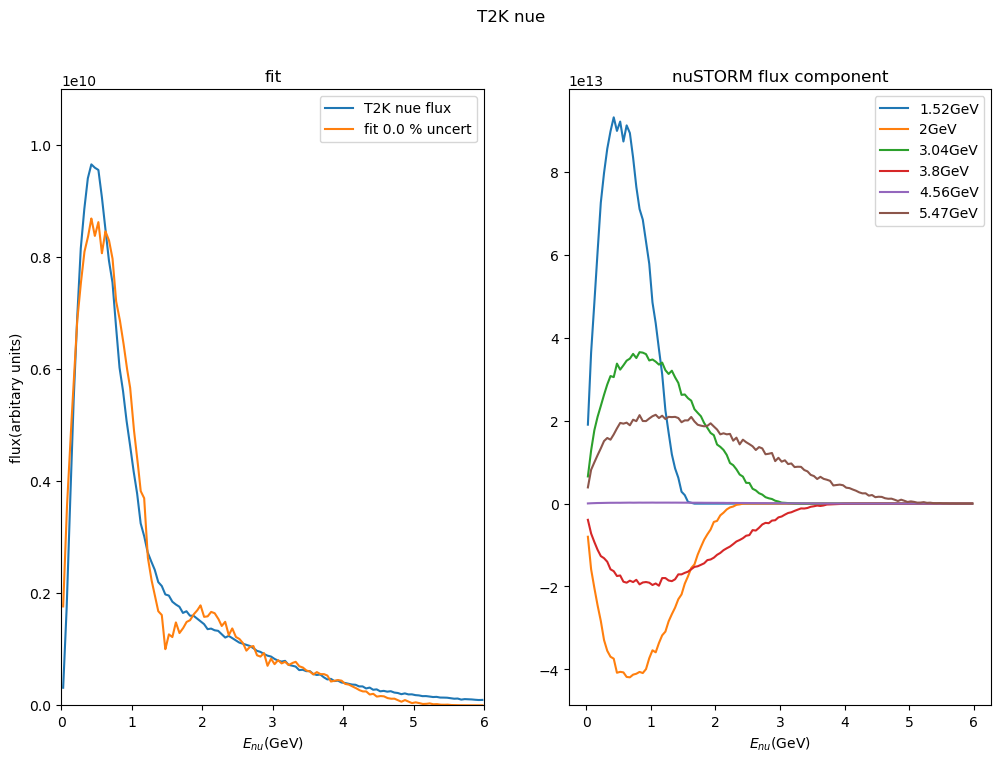

In [36]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_T2K_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [37]:
"""
DUNE PRISM Tikhonov regularization with more study from 
https://lss.fnal.gov/archive/thesis/2000/fermilab-thesis-2023-21.pdf page 204-
f:target flux
"""
def nue_opt_all_flux_get_FOM_DUNE_PRISM_v2(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    T_para = 1e-1 #coeff derivative
    weight = np.zeros(len(nu_E))
    flux_sum_before = 0 #flux sum of last nu_E
    if uniform_weight:
        for i in range(0,len(nu_E)):
            weight[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            flux_sum = 0
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                if j == len(coeff_lst)-1:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j])**2
                else:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j]-T_para*coeff_lst[j+1])**2
            
            weight[i] = (y[i]-flux_sum)**2
            #print(str(weight[i])+", "+str(nu_E[i]))
            
    return weight

def nue_opt_flux_FOM_fun_DUNE_PRISM_v2(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    weight = np.zeros(len(nu_E))
    weight = nue_opt_all_flux_get_FOM_DUNE_PRISM_v2(coeff_lst, nu_E, y, beam_uncert, uniform_weight)
    
    #print(sum(weight))
    return sum(weight)#weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

2.282355861469541e+19
[2.10819301e+18 2.88629204e+18 1.02908131e+18 9.30620473e+16
 4.39011427e+15 4.03667315e+17 5.95337897e+17 1.13054684e+18
 9.32921146e+17 1.48402224e+18 8.66314018e+17 9.95932492e+17
 1.25392602e+15 1.34377981e+17 1.93745702e+17 2.07806006e+17
 7.83173825e+17 8.33104416e+17 9.58317703e+17 1.08736779e+18
 6.17796830e+17 4.23751358e+17 3.33632621e+17 4.59591726e+17
 5.74395037e+15 9.49192382e+16 2.04146788e+17 2.70087970e+17
 2.67866643e+17 9.61698191e+17 4.79073122e+17 3.98968865e+17
 1.01527654e+17 2.21829338e+17 7.72492815e+16 3.69714986e+16
 6.67887503e+15 4.25982756e+14 1.95198784e+16 8.16652827e+16
 1.68072070e+16 5.18567955e+16 8.92056313e+16 9.36718849e+16
 4.89007405e+16 2.12241731e+16 7.94989748e+16 1.00017798e+14
 3.02920809e+16 3.85514019e+15 4.55402247e+15 2.54098385e+14
 1.08951289e+16 2.84868134e+14 1.50808110e+15 6.26571881e+15
 7.18297629e+15 2.82017990e+14 3.35240637e+16 1.41101763e+15
 9.06076779e+15 8.78437034e+13 1.06693947e+15 2.78374851e+14
 7

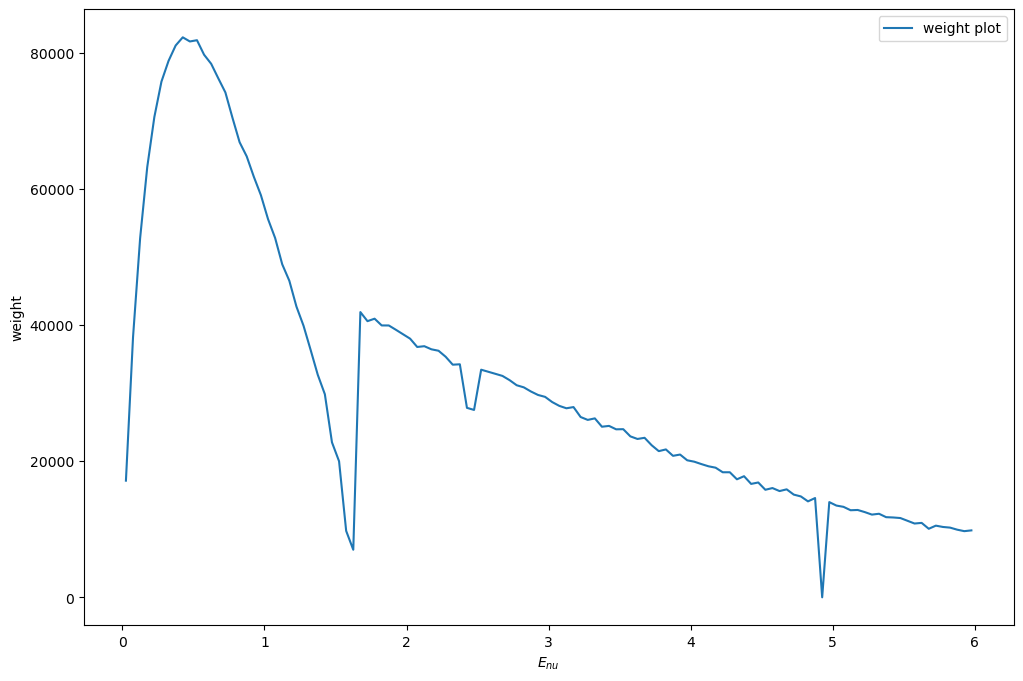

     message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [ 2.282e+19]
           x: [ 7.414e-01 -9.427e-02  5.679e-02 -2.948e-02  4.231e-04
                4.900e-02]
        cost: 2.6045741391921856e+38
         jac: [[ 2.890e+17 -1.625e+17  3.497e+17 -1.111e+17  2.704e+17
                 3.596e+16]]
        grad: [ 6.596e+36 -3.710e+36  7.981e+36 -2.537e+36  6.172e+36
                8.208e+35]
  optimality: 7.980675788252742e+36
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 20000
        njev: 19718


In [38]:
pars_0 = np.array([1.0, -1.0, 1.0, -1.0, 1.0, -1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_FOM_fun_DUNE_PRISM_v2, pars_0, args=(target_flux[:,0], target_flux[:,1],flux_uncert,False), max_nfev=20000)#, loss='cauchy', f_scale=0.1

print(nue_opt_flux_FOM_fun_DUNE_PRISM_v2(fit_lsq_nuSTORM_sigma_sim.x,target_flux[:,0], target_flux[:,1],flux_uncert,False))
print(nue_opt_all_flux_get_FOM_DUNE_PRISM_v2(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False))
plt.plot(target_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

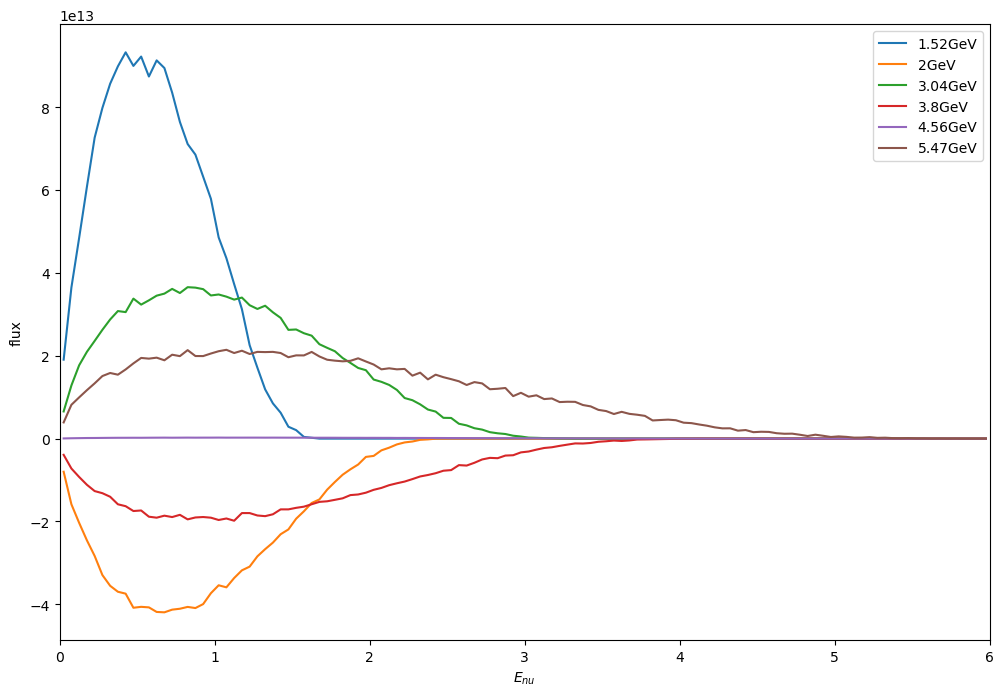

In [39]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_T2K_imitate.txt
coeff is : [ 7.41444766e-01 -9.42654979e-02  5.67938099e-02 -2.94767823e-02
  4.23113534e-04  4.90040024e-02]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.146055857431887 GeV
chi^2 of bin diff : 1.1998E+04


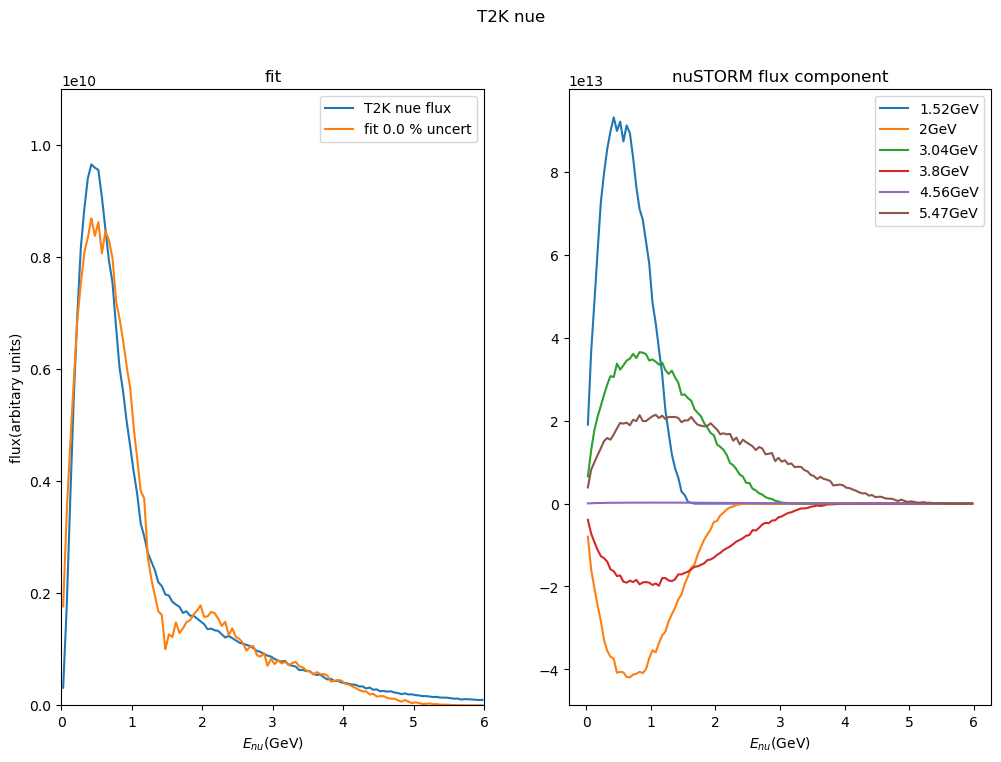

In [40]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_T2K_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [41]:
"""
DUNE PRISM Tikhonov regularization with more study from 
https://lss.fnal.gov/archive/thesis/2000/fermilab-thesis-2023-21.pdf page 204-
added penalty term for flux derivative
f:target flux
"""
def nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    T_para = 1e-1 #coeff derivative
    T_para2 = 3 #flux derivative
    weight = np.zeros(len(nu_E))
    flux_sum_before = 0 #flux sum of last nu_E
    if uniform_weight:
        for i in range(0,len(nu_E)):
            weight[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            flux_sum = 0
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                if j == len(coeff_lst)-1:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j])**2
                else:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j]-T_para*coeff_lst[j+1])**2
            
            weight[i] = (y[i]-flux_sum)**2 + T_para2*(flux_sum - flux_sum_before)**2
            flux_sum_before = flux_sum
            #print(str(weight[i])+", "+str(nu_E[i]))
            
    return weight

def nue_opt_flux_FOM_fun_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    weight = np.zeros(len(nu_E))
    weight = nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert, uniform_weight)
    
    #print(sum(weight))
    return sum(weight)#weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

6.579226160508223e+19
[1.07304189e+19 9.96347911e+18 3.86245513e+18 3.44584246e+18
 3.24744671e+18 2.37920174e+18 2.50567739e+18 2.71631873e+18
 2.47842664e+18 2.90703620e+18 2.03482063e+18 1.93595795e+18
 4.41414485e+17 8.45500218e+16 5.31912911e+17 1.05096957e+18
 7.20916443e+17 9.11378595e+17 1.27089345e+18 1.33671010e+18
 1.93550726e+18 1.20017737e+18 1.37704612e+18 9.11909254e+17
 1.67396592e+18 3.54586079e+17 5.10006972e+17 1.99807394e+17
 1.80300347e+17 5.79900739e+17 2.02860446e+17 2.12848838e+17
 1.11091082e+17 1.27591942e+17 4.46250630e+16 4.68324081e+16
 1.50570521e+16 1.11114829e+16 1.20663431e+16 4.17022900e+15
 1.04342194e+16 1.88587055e+16 1.88145416e+16 1.90248329e+16
 2.18590693e+16 5.01959378e+16 4.06543028e+16 4.73745570e+16
 3.74582331e+16 2.68393815e+16 2.05740074e+16 1.55218672e+16
 1.46000747e+16 3.36897296e+15 7.33832864e+15 2.67148598e+16
 3.70971854e+15 4.80408839e+15 5.01490974e+16 2.74074345e+15
 1.32198951e+16 4.64404510e+15 2.79776042e+16 1.35306181e+15
 8

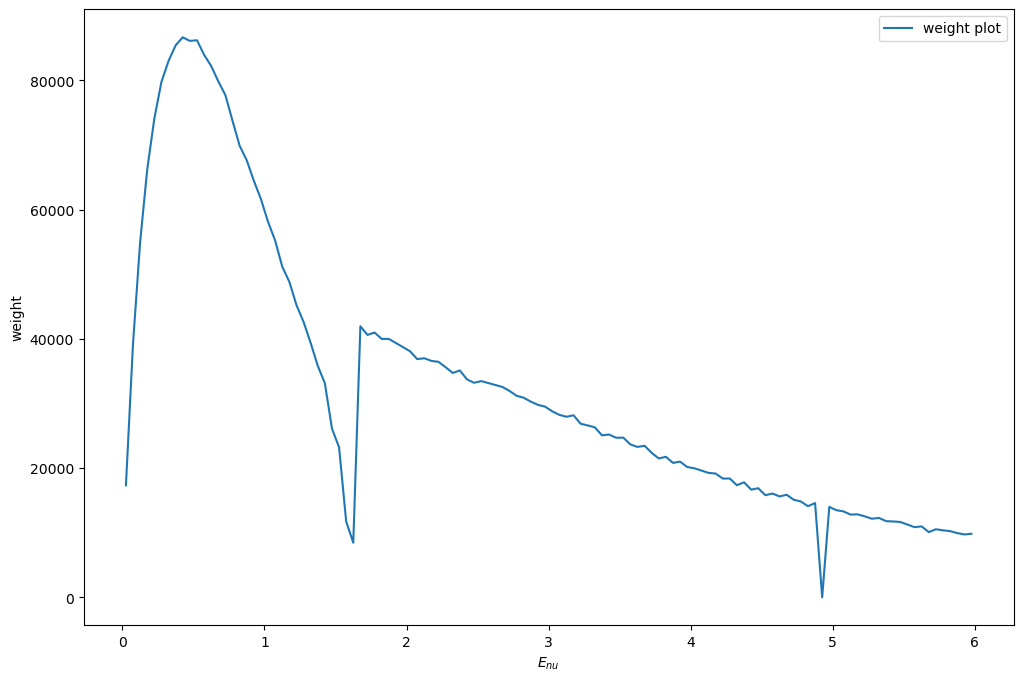

     message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [ 6.579e+19]
           x: [ 6.095e-01 -2.960e-02  3.507e-03  4.032e-04  1.073e-02
                2.907e-02]
        cost: 2.1643108435557886e+39
         jac: [[ 4.890e+17 -5.516e+17 -2.309e+17 -5.627e+17 -4.472e+17
                -3.664e+17]]
        grad: [ 3.218e+37 -3.629e+37 -1.519e+37 -3.702e+37 -2.942e+37
               -2.411e+37]
  optimality: 3.7022921037950056e+37
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 10000
        njev: 9874


In [42]:
pars_0 = np.array([1.0, -1.0, 1.0, -1.0, 1.0, -1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_FOM_fun_DUNE_PRISM_v3, pars_0, args=(target_flux[:,0], target_flux[:,1],flux_uncert,False), max_nfev=10000)#, loss='cauchy', f_scale=0.1

print(nue_opt_flux_FOM_fun_DUNE_PRISM_v3(fit_lsq_nuSTORM_sigma_sim.x,target_flux[:,0], target_flux[:,1],flux_uncert,False))
print(nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False))
plt.plot(target_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, target_flux[:,0], target_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

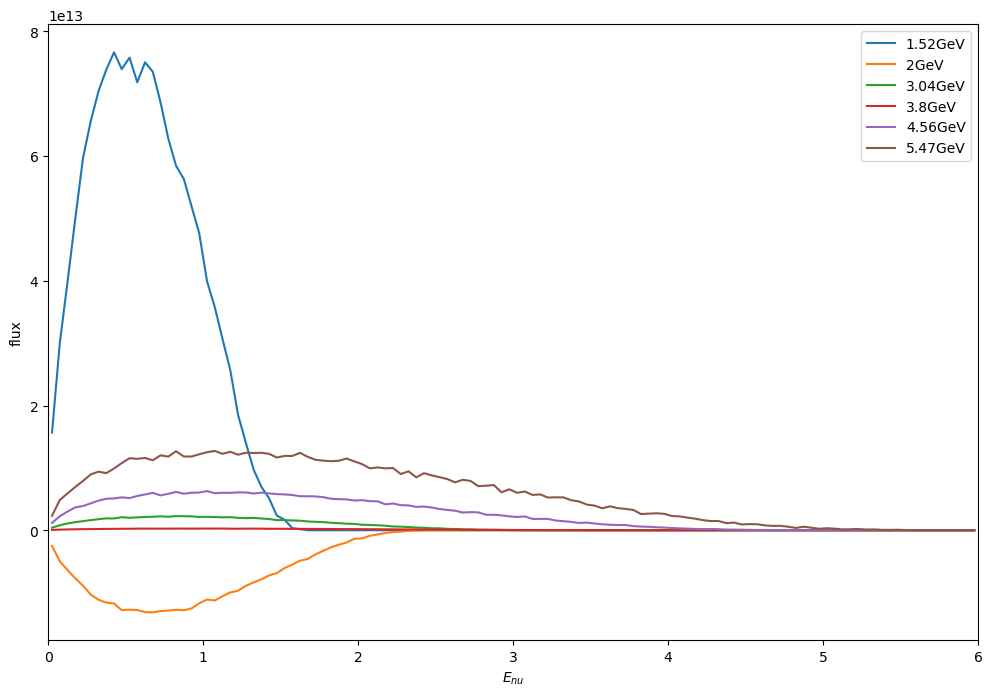

In [43]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_T2K_imitate.txt
coeff is : [ 6.09516261e-01 -2.95984352e-02  3.50697664e-03  4.03196032e-04
  1.07324042e-02  2.90732894e-02]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.129646804510035 GeV
chi^2 of bin diff : 1.1998E+04


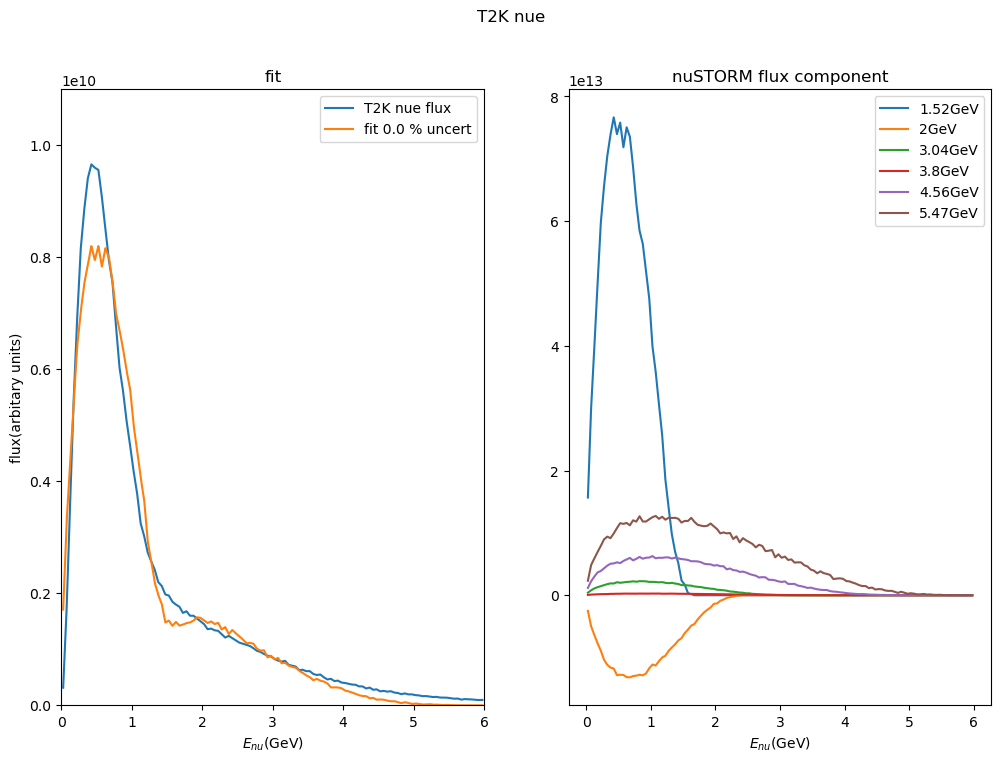

In [44]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_T2K_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [45]:
#osc test
def get_PMNS_matrix(kNuType):
    x12    = 0.302
    x13    = 0.0238
    x23    = 0.5
    m21    = 7.9e-5
    mAtm   = 2.5e-3
    delta  = 0.
    kSquared = True
    kOneDominantMass = True
    kSuppressWarnings = True

    fx12      = x12   
    fx13      = x13   
    fx23      = x23   
    fm21      = m21   
    fmAtm     = mAtm   
    fdelta    = delta 
    fSquared  = kSquared 
    
    #double sin12
    #double sin13
    #double sin23
    
    #if xAB = sin( xAB )^2
    if ( kSquared ):
    
        sin12 =  x12 
        sin13 =  x13 
        sin23 =  x23 
    
    else:
    
        #if xAB = sin( 2 xAB )^2
        # Default is to specify sin(x) in the first octant 
        # but this may be changed by the user to the second octant 
        # (mostly only an issue for atmospheric mixing) 
        if( kSx12Octant == 1 ):
            sin12 = np.sqrt( 0.5*(1 - np.sqrt(1 - x12 )))   
        else:
            sin12 = np.sqrt( 0.5*(1 + np.sqrt(1 - x12 )))   
        
        if( kSx13Octant == 1 ):
            sin13 = np.sqrt( 0.5*(1 - np.sqrt(1 - x13 )))   
        else:
            sin13 = np.sqrt( 0.5*(1 + np.sqrt(1 - x13 )))   
        
        if( kSx23Octant == 1 ):
            sin23 = np.sqrt( 0.5*(1 - np.sqrt(1 - x23 )))   
        else:
            sin23 = np.sqrt( 0.5*(1 + np.sqrt(1 - x23 )))   
        
        # LIV Routines expect sin^2 
        #  
        sin12 *= sin12 
        sin13 *= sin13 
        sin23 *= sin23 

    
    
    if ( kNuType < 0 ):
        
        delta *= -1.0 
        kAntiMNSMatrix = True 
        
    else: 
    
        kAntiMNSMatrix = False 

    
    #SetLVUPMNSmatrix( sin12, sin23, sin13, delta)
    th12=np.arcsin(np.sqrt(sin12))
    c12=np.cos(th12)
    s12=np.sin(th12)
    
    th23=np.arcsin(np.sqrt(sin23))
    c23=np.cos(th23)
    s23=np.sin(th23)
    
    th13=np.arcsin(np.sqrt(sin13))
    c13=np.cos(th13)
    s13=np.sin(th13)

    comp_i = 1j
    delta = delta*comp_i
    
    fPMNS = np.zeros((3,3),dtype=np.complex128)#np.array([[0+0j,0+0j,0+0j],[0+0j,0+0j,0+0j],[0+0j,0+0j,0+0j]])
    fPMNS[0][0]= c12*c13
    fPMNS[1][0]=-s12*c23 - c12*s23*s13*np.exp(-delta)
    fPMNS[2][0]= s12*s23 - c12*c23*s13*np.exp(-delta)
    fPMNS[0][1]= s12*c13
    fPMNS[1][1]= c12*c23 - s12*s23*s13*np.exp(-delta)
    fPMNS[2][1]=-c12*s23 - s12*c23*s13*np.exp(-delta)
    fPMNS[0][2]= s13*np.exp(delta)
    fPMNS[1][2]= s23*c13
    fPMNS[2][2]= c23*c13

    return fPMNS

def single_nu_osc(E, L, kNuType): #kNuType 0:e 1:mu 2:tau

    x12    = 0.302
    x13    = 0.0238
    x23    = 0.5
    m21    = 7.9e-5
    mAtm   = 2.5e-3
    delta  = 0.
    energy = E
    kSquared = True
    kOneDominantMass = True
    kSuppressWarnings = True

    PMNS_matrix = get_PMNS_matrix(kNuType)

    fx12      = x12   
    fx13      = x13   
    fx23      = x23   
    fm21      = m21   
    fmAtm     = mAtm   
    fdelta    = delta 
    fSquared  = kSquared 
    
    #double sin12
    #double sin13
    #double sin23
    
    fm31 = mAtm + m21 
    # Dominant Mixing mode assumes the user 
    # simply changes the sign of the input atmospheric 
    # mixing to invert the hierarchy 
    #  so the input for  NH corresponds to m32  
    # and the input for  IH corresponds to m31
    if( kOneDominantMass ):
    
        # For the inverted Hierarchy, adjust the input
        # by the solar mixing (should be positive) 
        # to feed the core libraries the correct value of m32
        if( mAtm < 0.0 ):  
            fm31 = mAtm - m21 
    
        else: 
    
            if( not(kSuppressWarnings) ):
            
                print(" FullSMEPropagator::SetMNS - ")    
                print("     You have opted to specify the value of m23 by yourself. ")        
                print("     This means you must correct the value of m23 when switching ")  
                print("     between the mass hierarchy options. ")  
                print("     This message can be suppressed with FullSMEPropagator::::SuppressWarnings()") 
    
    
    fDM2 = np.zeros(3)
    fDM2[0] = 0     
    fDM2[1] = m21  
    fDM2[2] = fm31 

    p_a_to_b = np.zeros(3)

    for nu_type in range(0,3):
        if kNuType == nu_type:
            p_a_to_b[nu_type] = p_a_to_b[nu_type] + 1
        for k in range(0,3):
            for j in range(k+1,3):
                matrix_mult = np.conjugate(PMNS_matrix[kNuType][j])*PMNS_matrix[nu_type][j]*PMNS_matrix[kNuType][k]*np.conjugate(PMNS_matrix[nu_type][k])
                if E<1e-8:
                    delta_jk_L_over_E = 1.2667*(fDM2[j]-fDM2[k])*L/1e-8
                else:
                    delta_jk_L_over_E = 1.2667*(fDM2[j]-fDM2[k])*L/E
                p_a_to_b[nu_type] = p_a_to_b[nu_type] - 4*matrix_mult.real*(np.sin(delta_jk_L_over_E)**2) + 2*matrix_mult.imag*np.sin(2*delta_jk_L_over_E)

    return p_a_to_b

def nu_flux_osc(flux, L, kNuType): #kNuType 0:e 1:mu 2:tau
    #flux in format([[E1,flux1],[E2,flux2]... ...]
    nue_flux = np.zeros((len(flux),2))
    numu_flux = np.zeros((len(flux),2))
    nutau_flux = np.zeros((len(flux),2))

    for i in range(0,len(flux)):
        #single_nu_osc(E, L, kNuType): L-km E-GeV dm^2-ev^2
        prob = single_nu_osc(flux[i][0], L, kNuType)

        nue_flux[i] = [flux[i][0], flux[i][1]*prob[0]]
        numu_flux[i] = [flux[i][0], flux[i][1]*prob[1]]
        nutau_flux[i] = [flux[i][0], flux[i][1]*prob[2]]

    return nue_flux, numu_flux, nutau_flux

In [46]:
comp_i = 1j
np.exp(comp_i*np.pi)
np.zeros((3,3),dtype=np.complex128)
np.zeros((5,2))

array([[0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.]])

[[ 0.82546205+0.j  0.5429663 +0.j  0.15427249+0.j]
 [-0.47972554+0.j  0.53081391+0.j  0.69864154+0.j]
 [ 0.29744883+0.j -0.65071053+0.j  0.69864154+0.j]]
[0.37029316 0.46982111 0.15988573]


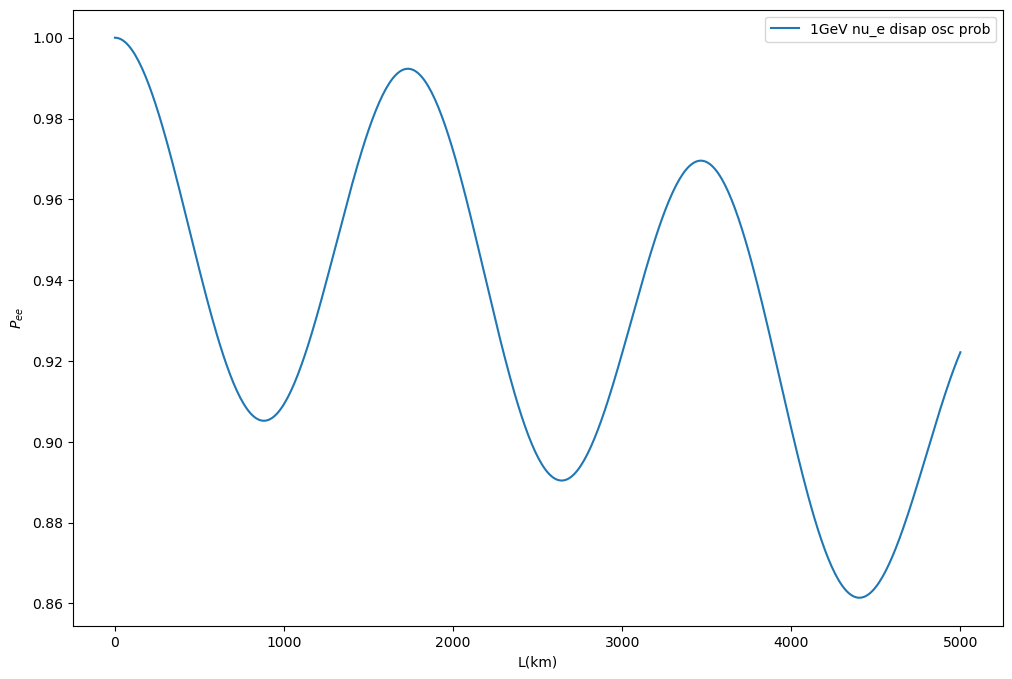

In [47]:
print(get_PMNS_matrix(1))
#single_nu_osc(E, L, kNuType): L-km E-GeV dm^2-ev^2
print(single_nu_osc(1,10000,0))
L_lst = np.linspace(0,5000,500)
P_ee_lst = np.zeros(500)
for i in range(0, len(L_lst)):
    P_ee_lst[i] = single_nu_osc(1.8,L_lst[i],0)[0]

plt.plot(L_lst, P_ee_lst, label='1GeV nu_e disap osc prob')
plt.xlabel("L(km)")
plt.ylabel("$P_{ee}$")
plt.legend()
plt.show()

In [48]:
DUNE_nue_numode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat")
DUNE_nue_antinumode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat")
DUNE_numu_numode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_numuFlux_numode.dat")
DUNE_numu_antinumode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_numuFlux_antinumode.dat")

the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat list is : 319
the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat list is : 319
the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_numuFlux_numode.dat list is : 319
the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_numuFlux_antinumode.dat list is : 319


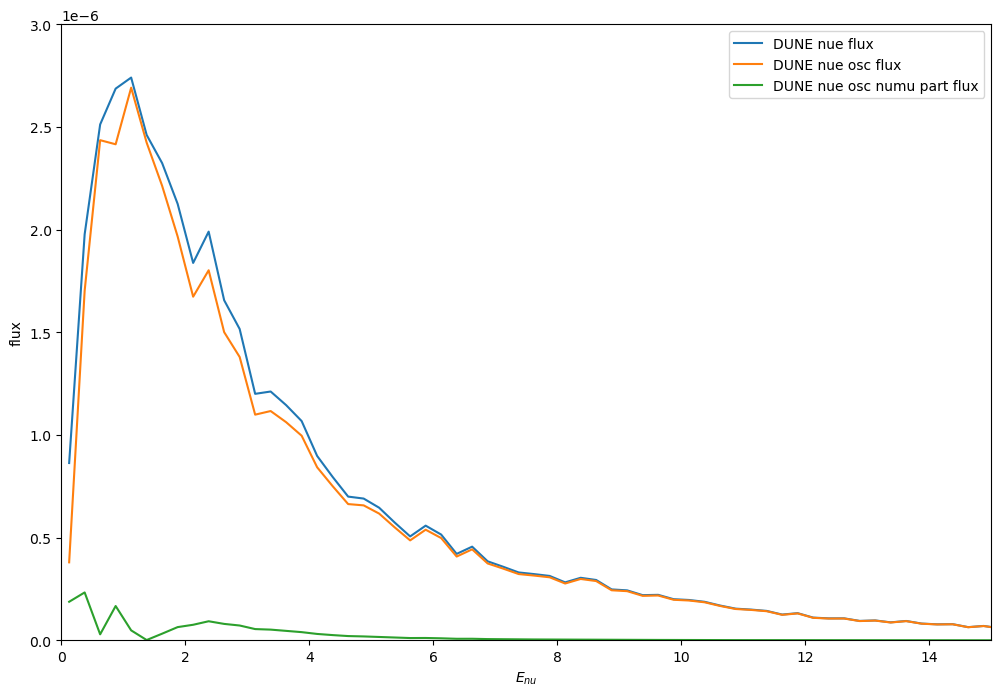

In [49]:
nue_osc, numu_osc, nutau_osc = nu_flux_osc(DUNE_nue_numode_flux, 1200, 0)#(flux, L, kNuType)
DUNE_nue_numode_flux_osc = nue_osc
DUNE_nue_numode_flux_osc_numu = numu_osc

plt.plot(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],label='DUNE nue flux')
plt.plot(DUNE_nue_numode_flux_osc[:,0], DUNE_nue_numode_flux_osc[:,1],label='DUNE nue osc flux')
plt.plot(DUNE_nue_numode_flux_osc_numu[:,0], DUNE_nue_numode_flux_osc_numu[:,1],label='DUNE nue osc numu part flux')
plt.xlim(0,15)
plt.ylim(0,3e-6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

[ 1076.16465512   711.11701832   630.91069633   610.06875626
   604.0495077    637.41103675   655.98175226   685.91070136
   737.62726125   708.8123353    777.02213032   812.10898457
   912.71140116   908.44727922   934.41354477   967.76640226
  1055.34931983  1121.0043313   1195.28210453  1203.52814529
  1244.38395333  1320.07153398  1405.80095895  1338.12692522
  1393.34558542  1541.29873204  1480.63079852  1612.24439285
  1670.64334857  1739.33762624  1760.8207163   1785.79143858
  1882.17807427  1812.17337091  1844.74241005  2008.38381516
  2027.37699653  2132.0775194   2124.85406246  2234.70563128
  2256.28889256  2308.9803733   2430.30131768  2546.00007619
  2584.77470769  2641.87465383  2823.34966997  2749.63820328
  3006.67997397  3057.99186066  3056.75380081  3252.05431168
  3212.35468688  3380.50590834  3258.36702476  3501.78251395
  3582.66559451  3565.34877808  3945.95437086  3779.23755538
  4113.30916256  4371.16178035  4518.72839159  4395.68229452
  4480.80210542  5097.64

C:\Users\peter\AppData\Local\Temp\ipykernel_55364\789776702.py:16: RuntimeWarning: invalid value encountered in scalar divide
  sigma[i] = sigma[i] + ((np.sqrt(y[i])+y[i]*beam_uncert)/y[i])**2


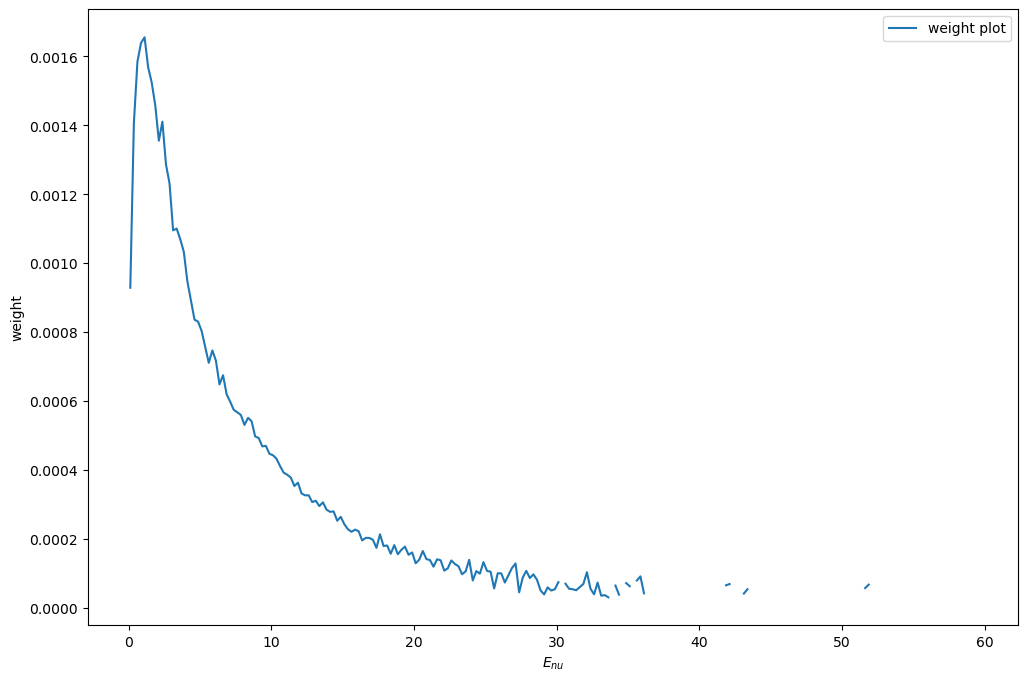

     message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [ 3.714e-07 -2.827e-07 ...  0.000e+00  0.000e+00]
           x: [ 4.196e-17  9.313e-19 -1.533e-17  5.769e-17 -1.318e-16
                1.615e-16]
        cost: 2.1769934783138794e-12
         jac: [[ 6.536e+09  2.158e+10 ...  2.788e+10  2.031e+10]
               [ 1.212e+10  3.921e+10 ...  4.710e+10  3.149e+10]
               ...
               [ 0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]
               [ 0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]]
        grad: [ 1.319e-11 -7.276e-11 -1.601e-10 -1.965e-10 -1.637e-10
               -1.510e-10]
  optimality: 1.964508555829525e-10
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 4
        njev: 4


In [50]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_sigma_fun, pars_0, args=(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],flux_uncert,True))#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],flux_uncert,False))
plt.plot(DUNE_nue_numode_flux[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

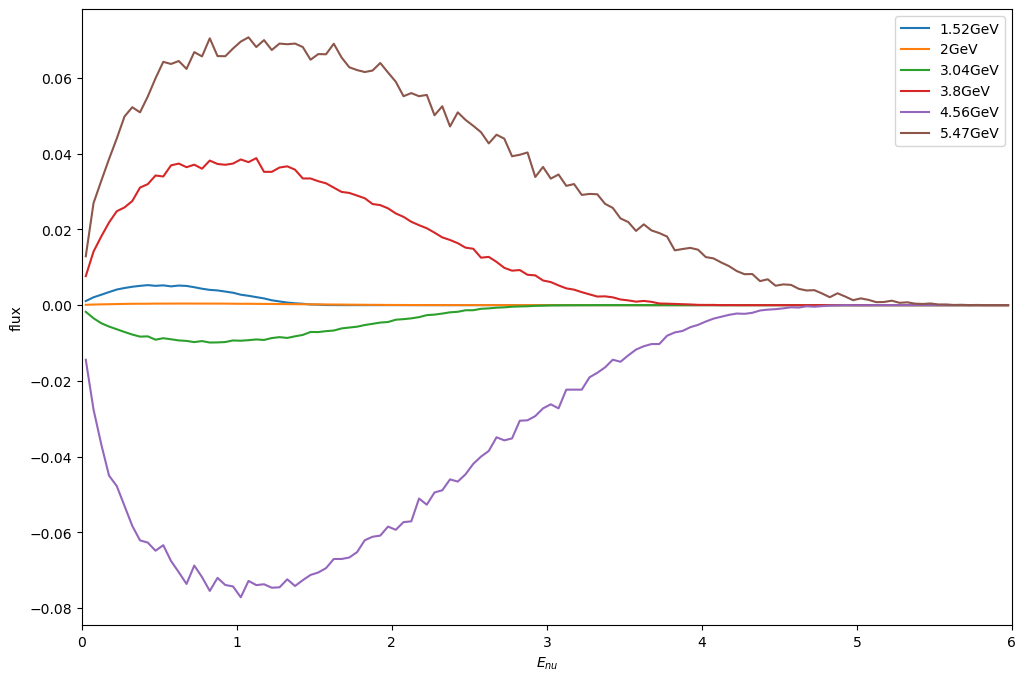

In [51]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

flux written to : nuSTORM_musig_nue_DUNE_imitate.txt
coeff is : [ 4.19550347e-17  9.31281430e-19 -1.53341093e-17  5.76899999e-17
 -1.31806531e-16  1.61547172e-16]
target flux $E_{nu}$ avg : 4.035832532667732 GeV fit flux $E_{nu}$ avg : 1.9595293528508275 GeV
chi^2 of bin diff : 4.3486E-05


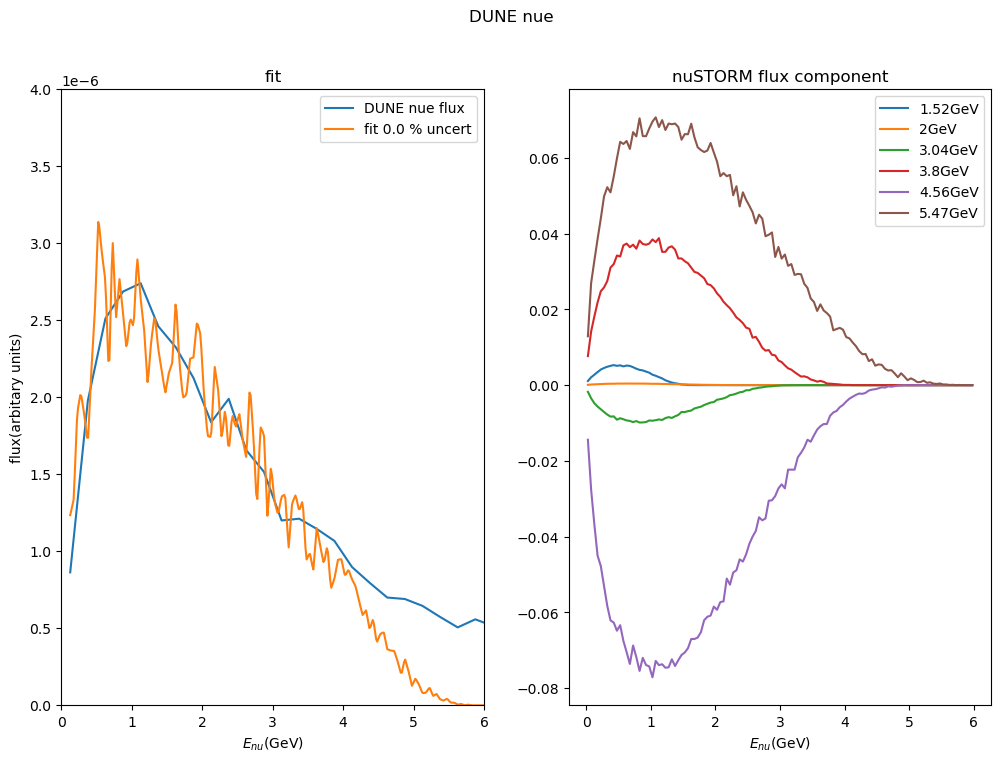

In [52]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_nue_numode_flux[:,0][0], DUNE_nue_numode_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
write_flux(fx, fy, 'nuSTORM_musig_nue_DUNE_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_nue_numode_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(DUNE_nue_numode_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,4e-6)
ax1.legend()
ax2.legend()
plt.show()

[0.00000000e+00 2.27015916e-09]
[6.01202405e-01 1.41349237e-08]
[1.20240481e+00 2.71429898e-08]
[1.80360721e+00 3.40181758e-08]
[2.40480962e+00 3.61125703e-08]
[3.00601202e+00 2.89236544e-08]
[3.60721443e+00 1.68050167e-08]
[4.20841683e+00 5.84380100e-09]
[4.80961924e+00 1.55075812e-09]
[5.41082164e+00 8.31215823e-10]


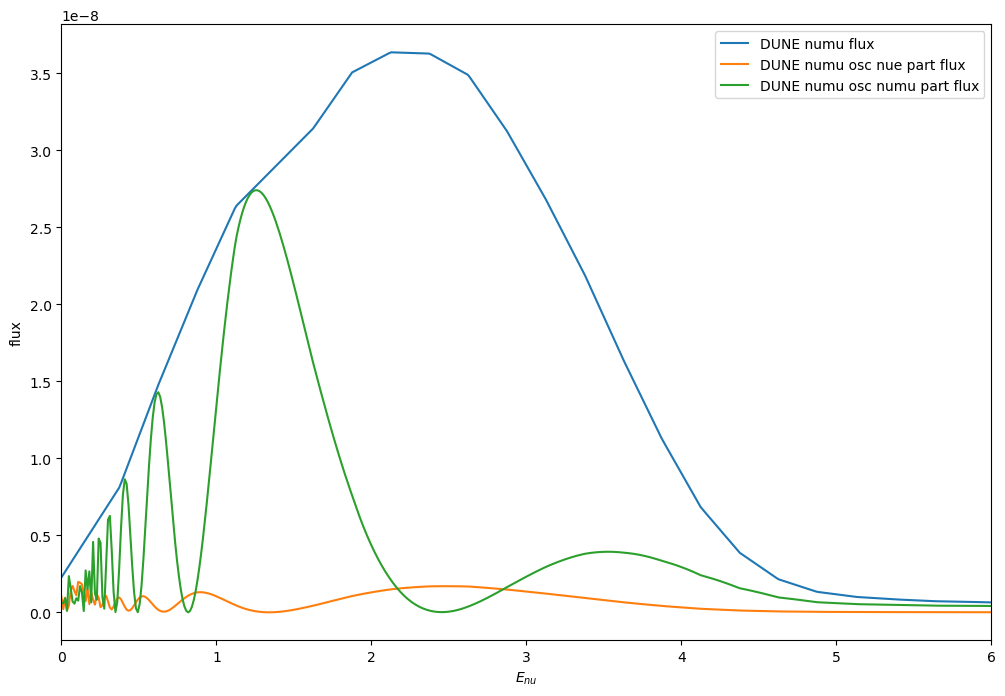

In [53]:
interpolate_leng = 500
interpolate_E = np.linspace(0,6,interpolate_leng)
DUNE_numu_numode_flux_interpolated = np.zeros((interpolate_leng,2))
interpolate_flux = get_flux_val_vect(DUNE_numu_numode_flux, interpolate_E)
for i in range(0,interpolate_leng):
    DUNE_numu_numode_flux_interpolated[i] = [interpolate_E[i], interpolate_flux[i]]
    if i%50 == 0:
        print(DUNE_numu_numode_flux_interpolated[i])

nue_osc, numu_osc, nutau_osc = nu_flux_osc(DUNE_numu_numode_flux_interpolated, 1200, 1)#(flux, L, kNuType)
DUNE_numu_numode_flux_osc = nue_osc
DUNE_numu_numode_flux_osc_numu = numu_osc

plt.plot(DUNE_numu_numode_flux_interpolated[:,0], DUNE_numu_numode_flux_interpolated[:,1],label='DUNE numu flux')
plt.plot(DUNE_numu_numode_flux_osc[:,0], DUNE_numu_numode_flux_osc[:,1],label='DUNE numu osc nue part flux')
plt.plot(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],label='DUNE numu osc numu part flux')
#plt.plot(nutau_osc[:,0], nutau_osc[:,1],label='DUNE numu osc nutau part flux')
plt.xlim(0,6)
#plt.ylim(0,5e-4)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

In [54]:

def numu_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    sigma = np.zeros(len(nu_E))
    if uniform_sigma:
        for i in range(0,len(nu_E)):
            sigma[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            sigma[i] = sigma[i] + ((np.sqrt(y[i])+y[i]*beam_uncert)/y[i])**2
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_numu_flux_lst[j], nu_E[i]))
                #print(flux_val)
                if not((flux_val == 0.0) or (coeff_lst[j] == 0)):
                    sigma[i] = sigma[i] + (coeff_lst[j]*((np.sqrt(flux_val)+flux_val*beam_uncert)/flux_val))**2
            #print(str(sigma[i])+", "+str(nu_E[i]))
            sigma[i] = np.abs(sigma[i])**0.5
            
    return sigma

def numu_opt_flux_sigma_fun(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    sigma = np.zeros(len(nu_E))
    sigma = numu_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert, uniform_sigma)
    
    weight = 1/sigma
    #print(trans)
    return weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.

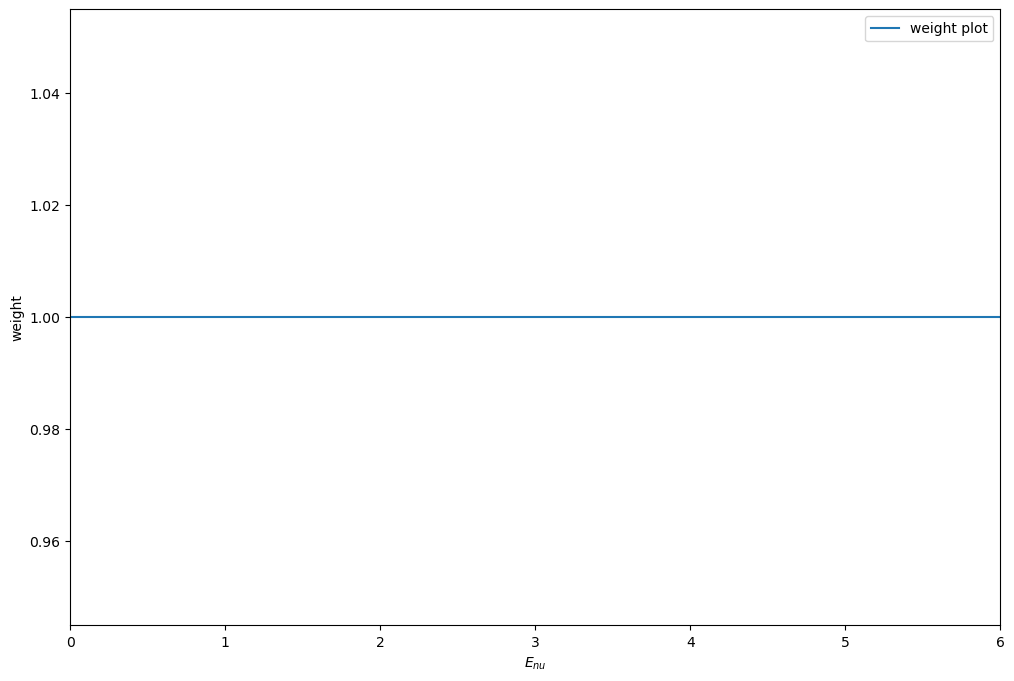

     message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.277e-09 -9.218e-10 ... -4.176e-10 -4.162e-10]
           x: [-3.235e-18  1.055e-18  1.054e-19 -2.648e-19 -7.328e-20
                3.116e-19]
        cost: 1.9950773773516426e-15
         jac: [[ 1.396e+09  4.321e+09 ...  5.946e+09  3.641e+09]
               [ 1.961e+09  6.324e+09 ...  8.344e+09  5.728e+09]
               ...
               [-0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]
               [-0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]]
        grad: [-8.242e-12 -4.072e-11 -1.122e-10 -1.189e-10 -1.018e-10
               -1.037e-10]
  optimality: 1.1893064311152557e-10
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 4
        njev: 4


In [55]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    numu_opt_flux_sigma_fun, pars_0, args=(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,True), max_nfev=50000)#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,True))
plt.plot(DUNE_numu_numode_flux_osc_numu[:,0],
         1/nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,True),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.xlim(0,6)
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

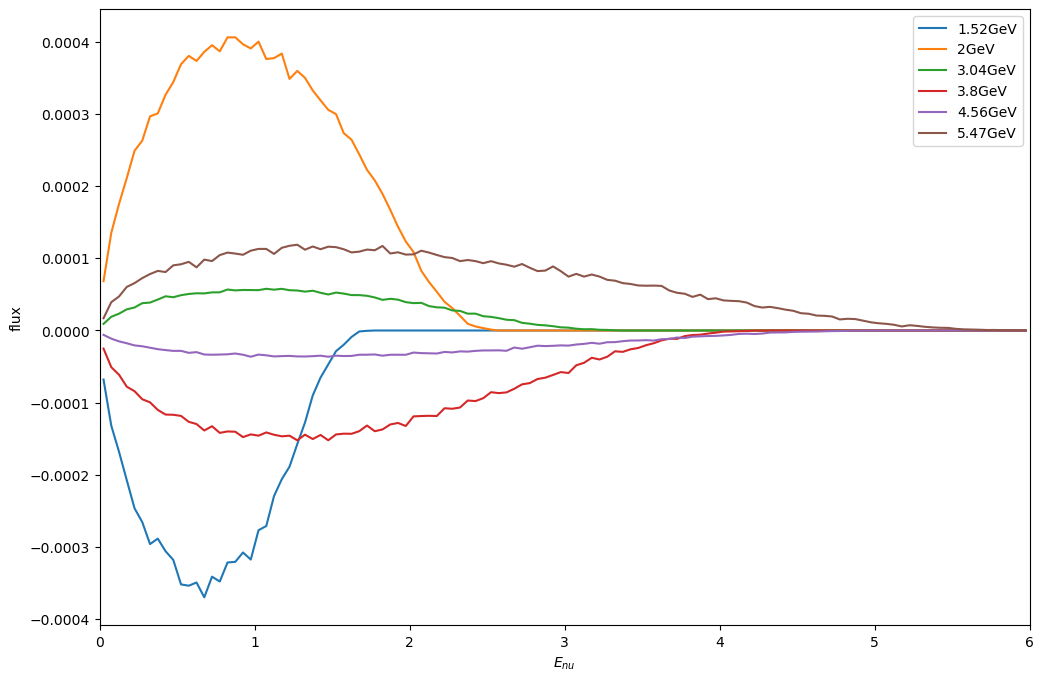

In [56]:
for i in range(0, len(nuSTORM_numu_flux_lst)):
    plt.plot(nuSTORM_numu_flux_lst[i][:,0], nuSTORM_numu_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [-3.23452104e-18  1.05529623e-18  1.05427532e-19 -2.64795245e-19
 -7.32760576e-20  3.11598482e-19]
target flux $E_{nu}$ avg : 1.7868556022324886 GeV fit flux $E_{nu}$ avg : 2.0025072209175834 GeV
chi^2 of bin diff : 2.4152E-06


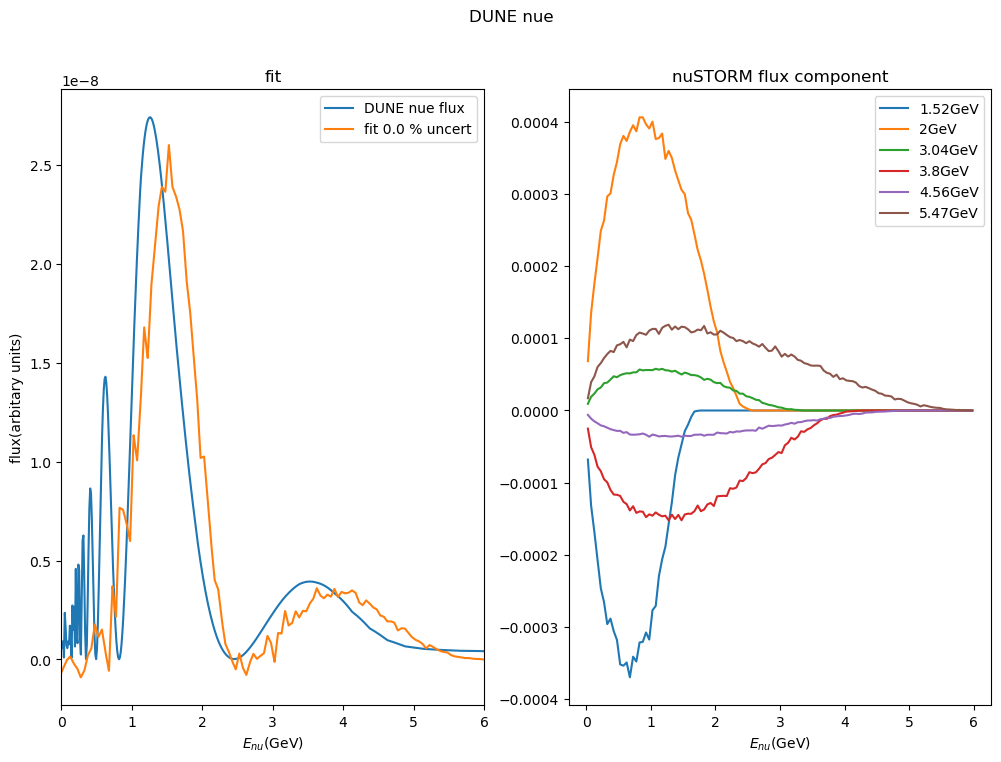

In [57]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_numu_numode_flux_osc_numu[:,0][0], DUNE_numu_numode_flux_osc_numu[:,0][-1], fit_lst_leng)
fy = sum_numu_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
#write_flux(fx, fy, 'nuSTORM_musig_nue_DUNE_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_numu_numode_flux_osc_numu)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(DUNE_numu_numode_flux_osc_numu, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_numu_flux_lst[i][:,0], nuSTORM_numu_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,4e-4)
ax1.legend()
ax2.legend()
plt.show()

In [58]:
"""
DUNE PRISM Tikhonov regularization with more study from 
https://lss.fnal.gov/archive/thesis/2000/fermilab-thesis-2023-21.pdf page 204-
added penalty term for flux derivative
f:target flux
"""
def nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    T_para = 0#1e-18 #coeff derivative
    T_para2 = 3e-2 #flux derivative
    weight = np.zeros(len(nu_E))
    flux_sum_before = 0 #flux sum of last nu_E
    if uniform_weight:
        for i in range(0,len(nu_E)):
            weight[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            flux_sum = 0
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_flux_lst[j], nu_E[i]))
                if j == len(coeff_lst)-1:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j])**2
                else:
                    flux_sum = flux_sum + flux_val*coeff_lst[j] + (T_para*coeff_lst[j]-T_para*coeff_lst[j+1])**2
            
            weight[i] = (y[i]-flux_sum)**2 + T_para2*(flux_sum - flux_sum_before)**2
            flux_sum_before = flux_sum
            #print(str(weight[i])+", "+str(nu_E[i]))
            
    return weight

def nue_opt_flux_FOM_fun_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert = 0., uniform_weight = False): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    weight = np.zeros(len(nu_E))
    weight = nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(coeff_lst, nu_E, y, beam_uncert, uniform_weight)
    
    #print(sum(weight))
    return sum(weight)#weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

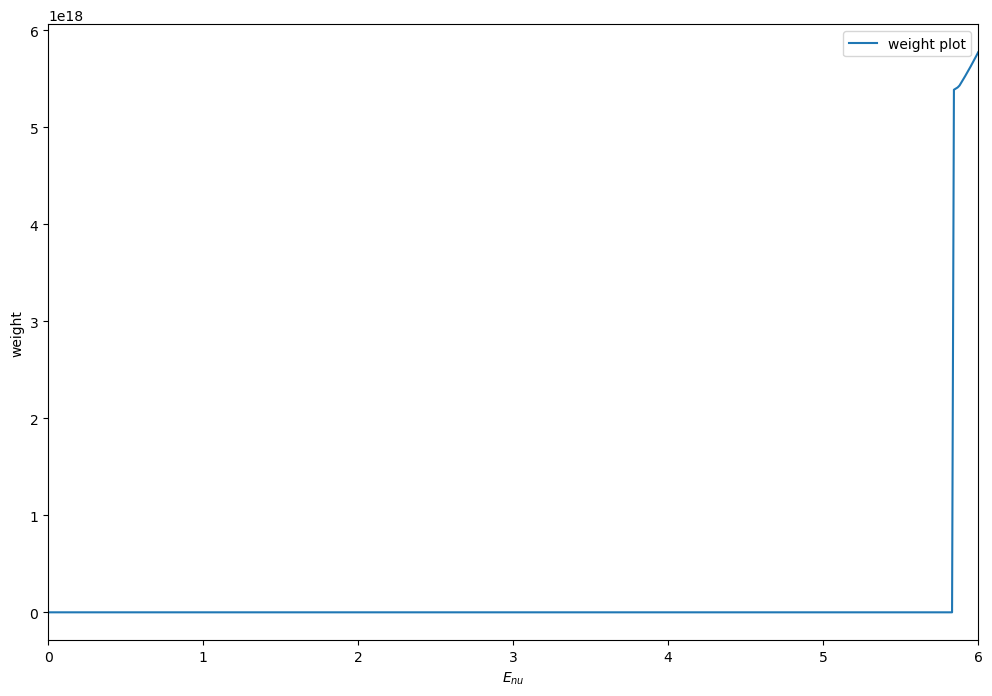

     message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [ 3.720e+14]
           x: [ 6.032e-04 -4.946e-04  5.634e-04 -5.548e-04  3.793e-04
               -1.319e-04]
        cost: 6.918712542068285e+28
         jac: [[ 2.917e+17 -5.285e+17 -1.318e+17 -8.072e+17 -2.934e+17
                -4.382e+17]]
        grad: [ 1.085e+32 -1.966e+32 -4.902e+31 -3.003e+32 -1.091e+32
               -1.630e+32]
  optimality: 3.0026179723698053e+32
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 20000
        njev: 19757


In [59]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
flux_uncert = 0.0
#numu_opt_flux_sigma_fun   nue_opt_all_flux_get_sigma   nue_opt_flux_FOM_fun_DUNE_PRISM_v3    nue_opt_all_flux_get_FOM_DUNE_PRISM_v3
fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    nue_opt_flux_FOM_fun_DUNE_PRISM_v3, pars_0, args=(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,False), max_nfev=20000)#, loss='cauchy', f_scale=0.1

#print(nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,False))
plt.plot(DUNE_numu_numode_flux_osc_numu[:,0],
         1/nue_opt_all_flux_get_FOM_DUNE_PRISM_v3(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.xlim(0,6)
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

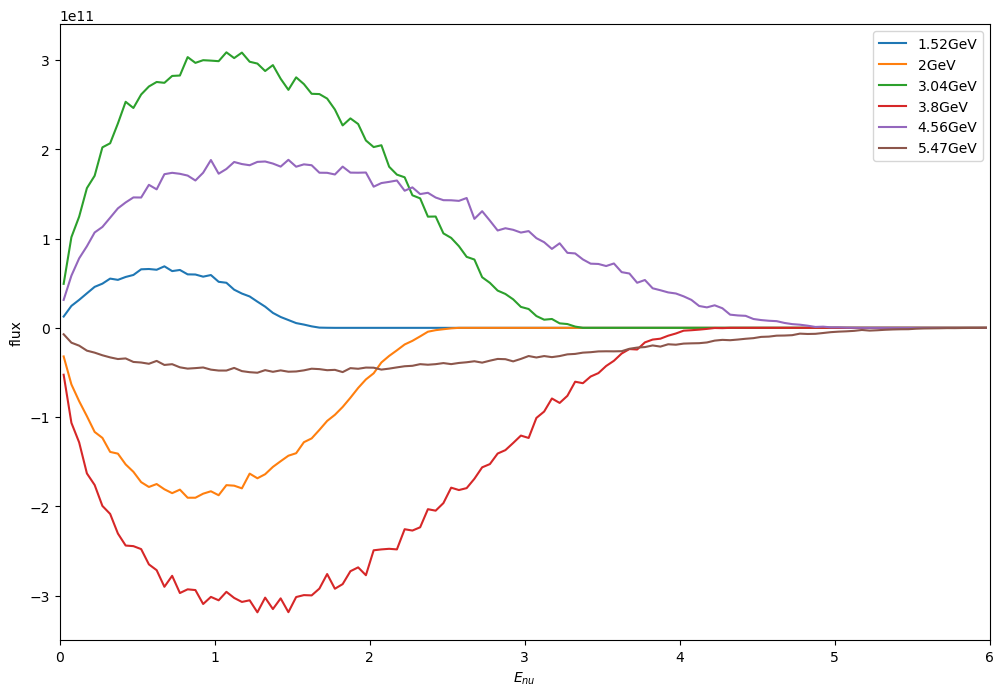

In [60]:
for i in range(0, len(nuSTORM_numu_flux_lst)):
    plt.plot(nuSTORM_numu_flux_lst[i][:,0], nuSTORM_numu_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 0.00060318 -0.00049459  0.00056339 -0.00055475  0.00037933 -0.0001319 ]
target flux $E_{nu}$ avg : 1.7868556022324886 GeV fit flux $E_{nu}$ avg : 9.034368388186673 GeV
chi^2 of bin diff : 1.9367E+16


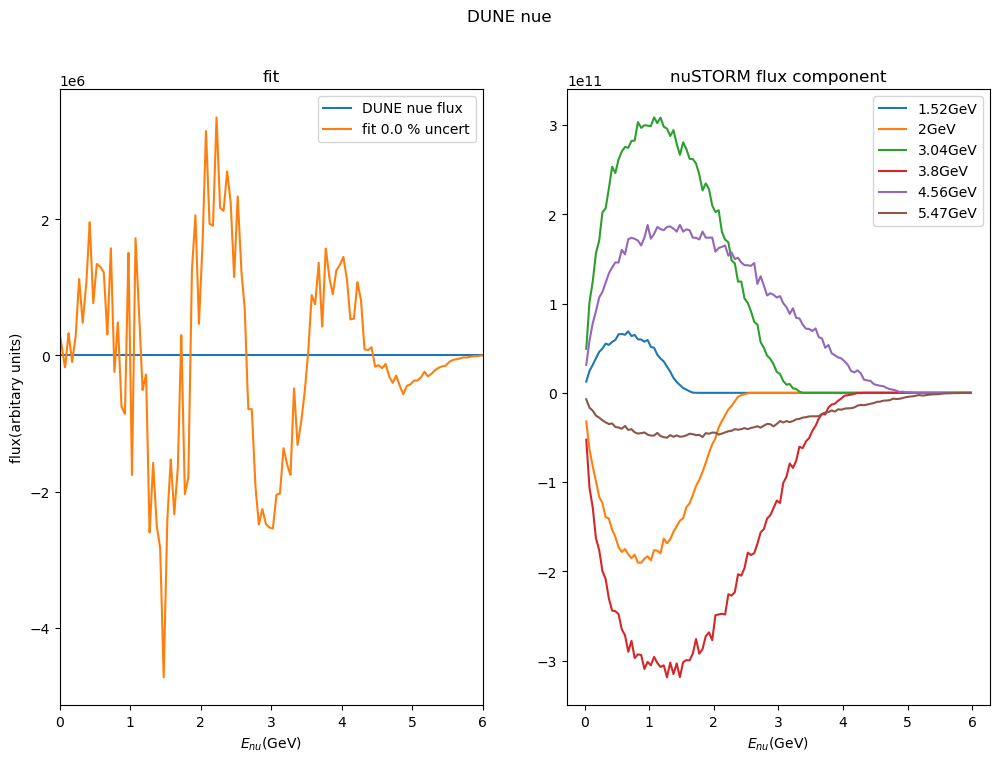

In [61]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_numu_numode_flux_osc_numu[:,0][0], DUNE_numu_numode_flux_osc_numu[:,0][-1], fit_lst_leng)
fy = sum_numu_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x) #calculate fitted function values
#write_flux(fx, fy, 'nuSTORM_musig_nue_DUNE_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_numu_numode_flux_osc_numu)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(DUNE_numu_numode_flux_osc_numu, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_numu_flux_lst[i][:,0], nuSTORM_numu_flux_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,4e-4)
ax1.legend()
ax2.legend()
plt.show()

In [62]:

def numu_PiFlash_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    sigma = np.zeros(len(nu_E))
    if uniform_sigma:
        for i in range(0,len(nu_E)):
            sigma[i] = 1.
    else:
        for i in range(0,len(nu_E)):
            sigma[i] = sigma[i] + ((np.sqrt(y[i])+y[i]*beam_uncert)/y[i])**2
            for j in range(0,len(coeff_lst)):
                flux_val = np.abs(get_flux_val(nuSTORM_PiFlash_lst[j], nu_E[i]))
                #print(flux_val)
                if not((flux_val == 0.0) or (coeff_lst[j] == 0)):
                    sigma[i] = sigma[i] + (coeff_lst[j]*((np.sqrt(flux_val)+flux_val*beam_uncert)/flux_val))**2
            #print(str(sigma[i])+", "+str(nu_E[i]))
            sigma[i] = np.abs(sigma[i])**0.5
            
    return sigma

def numu_PiFlash_opt_flux_sigma_fun(coeff_lst, nu_E, y, beam_uncert = 0., uniform_sigma = True): 
    #coeff_lst = [coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47]
    #beam_uncert is uncertainty of beam
    #uniform sigma if True it will just consider all sigma 1 if not will calc sigma for each bin
    
    #sum_flux = np.zeros(len(nu_E))
    sigma = np.zeros(len(nu_E))
    sigma = numu_PiFlash_opt_all_flux_get_sigma(coeff_lst, nu_E, y, beam_uncert, uniform_sigma)
    
    weight = 1/sigma
    #print(trans)
    return weight*(sum_flux_nu_E(nu_E, *coeff_lst) -y)

[ 40006.82498869  40938.76918443  32915.76351522 101090.9378082
  20600.31558729  25112.17377697  37686.6124605   41893.6345414
  33016.28842029  36203.81507094  24209.34812136  27655.25511993
 105077.68053566  19150.06638328  25830.96320276  19377.94819142
  39124.73152212  14779.19809355  28562.0869754   34906.59125944
  14440.7528664   14894.24376348  31475.14720656  63803.87586915
  17987.00734282  12887.19889275  12631.42750307  15737.47930061
  27286.30371563 206392.12887133  37690.68104086  18694.29112721
  13477.10131901  11436.29448727  10755.92876595  10945.99715376
  11960.10091286  14090.15051862  18269.71264639  27665.40874268
  61237.57382911 255284.97911463  42674.41824348  23857.0054445
  16997.62069927  13539.40404255  11521.1055503   10251.44111417
   9426.23400586   8892.3694622    8566.0054554    8399.12319277
   8364.38244046   8453.98017264   8656.14548537   8973.91626393
   9418.03190447  10008.14354273  10775.62903415  11768.87724357
  13062.9435994   14777.7502

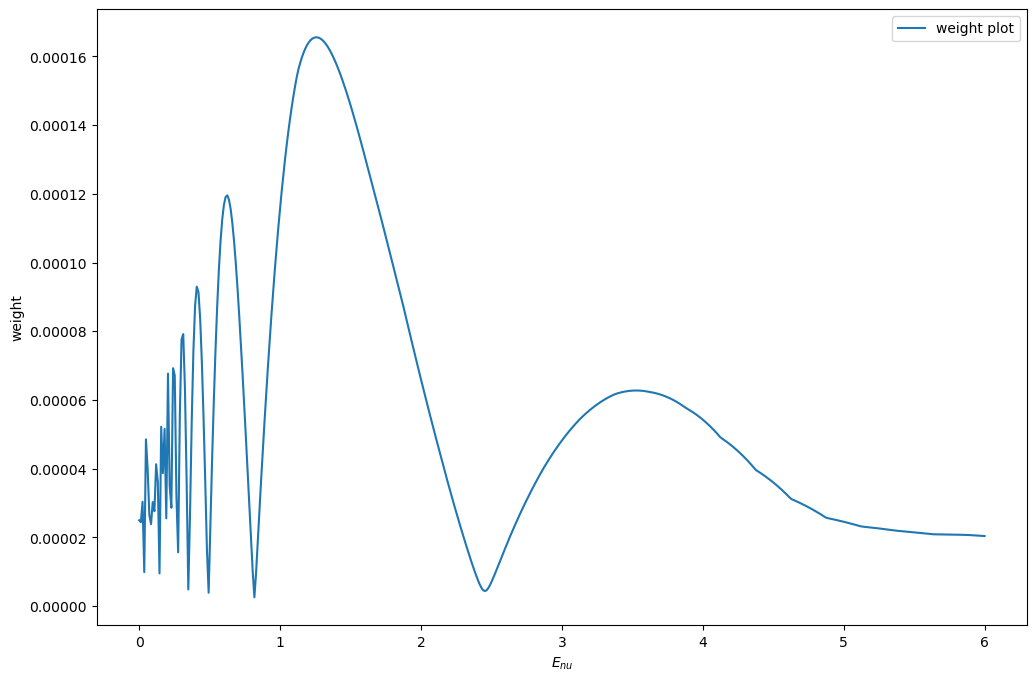

     message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.277e-09 -9.218e-10 ... -4.176e-10 -4.162e-10]
           x: [-3.235e-18  1.055e-18  1.054e-19 -2.648e-19 -7.328e-20
                3.116e-19]
        cost: 1.9950773773516426e-15
         jac: [[ 1.396e+09  4.321e+09 ...  5.946e+09  3.641e+09]
               [ 1.961e+09  6.324e+09 ...  8.344e+09  5.728e+09]
               ...
               [-0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]
               [-0.000e+00  0.000e+00 ... -0.000e+00  0.000e+00]]
        grad: [-8.242e-12 -4.072e-11 -1.122e-10 -1.189e-10 -1.018e-10
               -1.037e-10]
  optimality: 1.1893064311152557e-10
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00]
        nfev: 4
        njev: 4


In [63]:
pars_0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
flux_uncert = 0.0

fit_lsq_nuSTORM_sigma_sim = optimize.least_squares(
    numu_PiFlash_opt_flux_sigma_fun, pars_0, args=(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,True))#, loss='cauchy', f_scale=0.1

print(nue_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,False))
plt.plot(DUNE_numu_numode_flux_osc_numu[:,0],
         1/numu_PiFlash_opt_all_flux_get_sigma(fit_lsq_nuSTORM_sigma_sim.x, DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],flux_uncert,False),label='weight plot')
plt.xlabel("$E_{nu}$")
plt.ylabel("weight")
plt.legend()
plt.show()

print(fit_lsq_nuSTORM_sigma_sim)

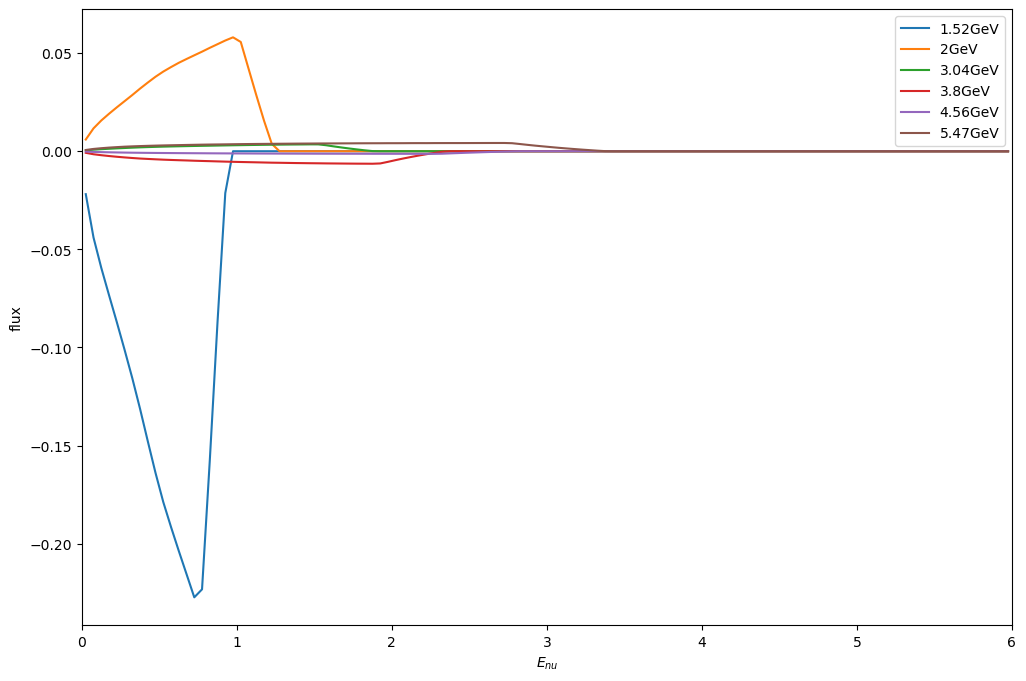

In [64]:
for i in range(0, len(nuSTORM_PiFlash_lst)):
    plt.plot(nuSTORM_PiFlash_lst[i][:,0], nuSTORM_PiFlash_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [-3.23452104e-18  1.05529623e-18  1.05427532e-19 -2.64795245e-19
 -7.32760576e-20  3.11598482e-19]
target flux $E_{nu}$ avg : 1.7868556022324886 GeV fit flux $E_{nu}$ avg : 0.3983467121266853 GeV
chi^2 of bin diff : 2.4158E-06


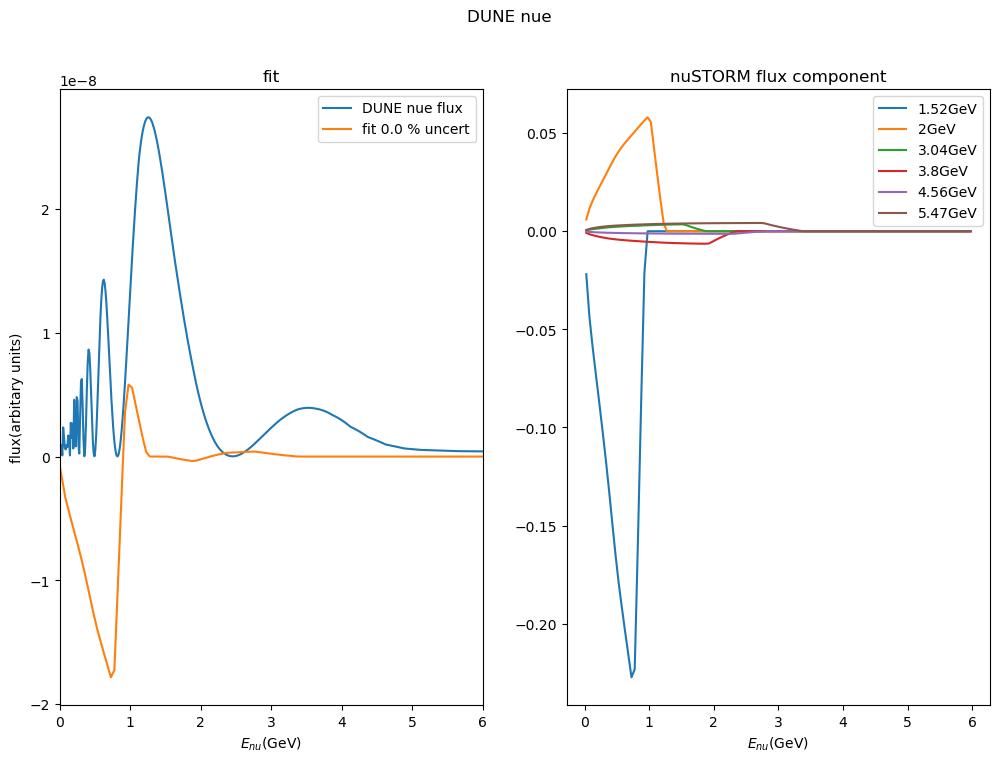

In [65]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_numu_numode_flux_osc_numu[:,0][0], DUNE_numu_numode_flux_osc_numu[:,0][-1], fit_lst_leng)
fy = sum_numu_PiFlash_flux_nu_E(fx, *fit_lsq_nuSTORM_sigma_sim.x)/1000 #calculate fitted function values
#write_flux(fx, fy, 'nuSTORM_musig_nue_DUNE_imitate.txt')
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_numu_numode_flux_osc_numu)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(fit_lsq_nuSTORM_sigma_sim.x))
#print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(DUNE_numu_numode_flux_osc_numu, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

fit_tit = 'fit '+str(flux_uncert*100)+' % uncert'
ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_numu_numode_flux_osc_numu[:,0], DUNE_numu_numode_flux_osc_numu[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label=fit_tit)

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_PiFlash_lst[i][:,0], nuSTORM_PiFlash_lst[i][:,1]*fit_lsq_nuSTORM_sigma_sim.x[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,4e-4)
ax1.legend()
ax2.legend()
plt.show()